In [1]:
# Cell 0 — paths
from pathlib import Path
import os, json, re, subprocess, collections
import pandas as pd, numpy as np

HOME    = Path.home()
ARCH    = HOME / "dataset_arch" / "SignLanguage"     # <-- edit if different
WORK    = HOME / "work" / "signlanguage"
REPORTS = WORK / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

STATIONS = ["stationA_2ndbatch", "stationB_2ndbatch"]
EXCEL_DIR = ARCH / "excel_2ndbatch"

for p in [ARCH, EXCEL_DIR] + [ARCH / s for s in STATIONS]:
    print(f"{'OK ' if p.exists() else 'MISSING'}  {p}")

OK   /home/soehn/dataset_arch/SignLanguage
OK   /home/soehn/dataset_arch/SignLanguage/excel_2ndbatch
OK   /home/soehn/dataset_arch/SignLanguage/stationA_2ndbatch
OK   /home/soehn/dataset_arch/SignLanguage/stationB_2ndbatch


In [2]:
# Cell 1 — inventory of batch 2 raw videos (PyAV)
import re, os
import av
import pandas as pd
from tqdm.auto import tqdm

FNAME = re.compile(r"^(\d+)-([a-zA-Z]+)_(\d{8})_(\d{6})$")   # 1-m_20260822_073232


def probe(path):
    """Read fps / frames / duration / size from one video file."""
    try:
        with av.open(str(path)) as c:
            st = next(s for s in c.streams if s.type == "video")
            fps = float(st.average_rate) if st.average_rate else None
            if c.duration:
                dur = float(c.duration / av.time_base)
            elif st.duration and st.time_base:
                dur = float(st.duration * st.time_base)
            else:
                dur = None
            return {
                "fps": round(fps, 3) if fps else None,
                "nb_frames": st.frames or None,      # 0 = not stored in header
                "duration": round(dur, 2) if dur else None,
                "w": st.codec_context.width,
                "h": st.codec_context.height,
                "codec": st.codec_context.name,
                "ok": True,
                "error": None,
            }
    except Exception as e:
        return {"fps": None, "nb_frames": None, "duration": None,
                "w": None, "h": None, "codec": None,
                "ok": False, "error": f"{type(e).__name__}: {e}"}


# ── collect the file list first, so tqdm can show a real total ──
todo = []
for station in STATIONS:
    sdir = ARCH / station
    if not sdir.is_dir():
        print(f"[skip] {station} not found")
        continue
    for cat in sorted(os.listdir(sdir)):
        cdir = sdir / cat
        if not cdir.is_dir():
            continue
        for v in sorted(cdir.iterdir()):
            if v.suffix.lower() == ".mp4":
                todo.append((station, cat, v))

print(f"{len(todo)} mp4 files found. Probing...")

# ── probe each one ──
rows = []
for station, cat, v in tqdm(todo):
    m = FNAME.match(v.stem)
    rec = {
        "station": station,
        "category": cat,
        "file": v.name,
        "path": str(v),
        "bytes": v.stat().st_size,
        "id": int(m.group(1)) if m else None,
        "stream": m.group(2).lower() if m else None,
        "date": m.group(3) if m else None,
        "time": m.group(4) if m else None,
        "name_ok": bool(m),
    }
    rec.update(probe(v))
    rows.append(rec)

df = pd.DataFrame(rows)
df.to_csv(REPORTS / "batch2_videos.csv", index=False)

print(f"\nScanned {len(df)} files  →  {REPORTS / 'batch2_videos.csv'}")
print(f"  readable      : {int((df.ok == True).sum())}")
print(f"  unreadable    : {int((df.ok != True).sum())}")
print(f"  bad filenames : {int((~df.name_ok).sum())}")
print(f"  missing fps   : {int(df.fps.isna().sum())}")
print(f"  missing frames: {int(df.nb_frames.isna().sum())}")
print(f"  total size    : {df.bytes.sum()/1e9:.1f} GB")

df.head(10)

4370 mp4 files found. Probing...


  0%|          | 0/4370 [00:00<?, ?it/s]


Scanned 4370 files  →  /home/soehn/work/signlanguage/reports/batch2_videos.csv
  readable      : 3039
  unreadable    : 1331
  bad filenames : 0
  missing fps   : 1331
  missing frames: 1331
  total size    : 17.1 GB


,station,category,file,path,bytes,id,stream,date,time,name_ok,fps,nb_frames,duration,w,h,codec,ok,error
0,stationA_2ndbatch,10_nutrition,1-m_20260830_102115.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,2097152,1,m,20260830,102115,True,NaN,NaN,NaN,NaN,NaN,None,False,InvalidDataError: [Errno 1094995529] Invalid d...
1,stationA_2ndbatch,10_nutrition,1-r_20260830_102115.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,802268,1,r,20260830,102115,True,30.0,178.0,5.93,640.0,480.0,mpeg4,True,None
2,stationA_2ndbatch,10_nutrition,10-m_20260830_102802.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,2097152,10,m,20260830,102802,True,NaN,NaN,NaN,NaN,NaN,None,False,InvalidDataError: [Errno 1094995529] Invalid d...
3,stationA_2ndbatch,10_nutrition,10-r_20260830_102802.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,1442396,10,r,20260830,102802,True,30.0,333.0,11.10,640.0,480.0,mpeg4,True,None
4,stationA_2ndbatch,10_nutrition,11-m_20260830_103359.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,2097152,11,m,20260830,103359,True,NaN,NaN,NaN,NaN,NaN,None,False,InvalidDataError: [Errno 1094995529] Invalid d...
5,stationA_2ndbatch,10_nutrition,11-r_20260830_103359.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,750207,11,r,20260830,103359,True,30.0,170.0,5.67,640.0,480.0,mpeg4,True,None
6,stationA_2ndbatch,10_nutrition,12-m_20260830_103451.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,2097152,12,m,20260830,103451,True,NaN,NaN,NaN,NaN,NaN,None,False,InvalidDataError: [Errno 1094995529] Invalid d...
7,stationA_2ndbatch,10_nutrition,12-r_20260830_103451.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,842127,12,r,20260830,103451,True,30.0,208.0,6.93,640.0,480.0,mpeg4,True,None
8,stationA_2ndbatch,10_nutrition,13-m_20260830_103538.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,2097152,13,m,20260830,103538,True,NaN,NaN,NaN,NaN,NaN,None,False,InvalidDataError: [Errno 1094995529] Invalid d...
9,stationA_2ndbatch,10_nutrition,13-r_20260830_103538.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,1096192,13,r,20260830,103538,True,30.0,253.0,8.43,640.0,480.0,mpeg4,True,None


In [11]:
# Cell 1 — scan RGB (-m) videos only
MB = 1024 * 1024
FNAME = re.compile(r"^(\d+)-([a-zA-Z]+)_(\d{8})_(\d{6})$")

def probe(path):
    try:
        with av.open(str(path)) as c:
            st = next(s for s in c.streams if s.type == "video")
            fps = float(st.average_rate) if st.average_rate else None
            if c.duration:
                dur = float(c.duration / av.time_base)
            elif st.duration and st.time_base:
                dur = float(st.duration * st.time_base)
            else:
                dur = None
            return {"fps": round(fps, 3) if fps else None,
                    "nb_frames": st.frames or None,
                    "duration": round(dur, 2) if dur else None,
                    "w": st.codec_context.width,
                    "h": st.codec_context.height,
                    "codec": st.codec_context.name,
                    "ok": True, "error": None}
    except Exception as e:
        return {"fps": None, "nb_frames": None, "duration": None,
                "w": None, "h": None, "codec": None,
                "ok": False, "error": f"{type(e).__name__}: {e}"}

# collect RGB files only
todo = []
for station in STATIONS:
    sdir = ARCH / station
    if not sdir.is_dir():
        print(f"[skip] {station} not found")
        continue
    for cat in sorted(os.listdir(sdir)):
        cdir = sdir / cat
        if not cdir.is_dir():
            continue
        for v in sorted(cdir.iterdir()):
            if v.suffix.lower() == ".mp4" and "-m_" in v.name:
                todo.append((station, cat, v))

print(f"{len(todo)} RGB (-m) files found. Reading...")

rows = []
for station, cat, v in tqdm(todo):
    mm = FNAME.match(v.stem)
    size = v.stat().st_size
    rec = {"station": station, "category": cat, "file": v.name, "path": str(v),
           "bytes": size,
           "exact_mb": size % MB == 0,              # truncation warning sign
           "id":   int(mm.group(1)) if mm else None,
           "date": mm.group(3) if mm else None,
           "time": mm.group(4) if mm else None,
           "name_ok": bool(mm)}
    rec.update(probe(v))
    rows.append(rec)

allm = pd.DataFrame(rows)
rgb  = allm[allm.ok == True].copy().sort_values(
          ["station", "category", "id"]).reset_index(drop=True)
bad  = allm[allm.ok != True].copy()

rgb.to_csv(REPORTS / "batch2_rgb.csv", index=False)
bad.to_csv(REPORTS / "batch2_rgb_broken.csv", index=False)

print("\n" + "="*60)
print(f"RGB files on server : {len(allm)}")
print(f"  GOOD (readable)   : {len(rgb)}")
print(f"  BROKEN            : {len(bad)}")
print(f"  still exact-MB    : {int(allm.exact_mb.sum())}   <- should be 0")
print(f"  total size        : {allm.bytes.sum()/1e9:.1f} GB")
print("="*60)

if len(bad):
    print("\nStill broken, by folder:")
    print(bad.groupby(["station", "category"]).size().to_string())
    print("\nFirst 15:")
    for _, r in bad.head(15).iterrows():
        print(f"  {r.station[:8]}/{r.category}/{r.file}  {r.bytes/1e6:.2f} MB")

print(f"\nSaved -> {REPORTS / 'batch2_rgb.csv'}")
rgb.head()

2320 RGB (-m) files found. Reading...


  0%|          | 0/2320 [00:00<?, ?it/s]


RGB files on server : 2320
  GOOD (readable)   : 2320
  BROKEN            : 0
  still exact-MB    : 0   <- should be 0
  total size        : 29.9 GB

Saved -> /home/soehn/work/signlanguage/reports/batch2_rgb.csv


,station,category,file,path,bytes,exact_mb,id,date,time,name_ok,fps,nb_frames,duration,w,h,codec,ok,error
0,stationA_2ndbatch,10_nutrition,1-m_20260830_102115.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,14021931,False,1,20260830,102115,True,120.0,775,6.46,1920,1080,mpeg4,True,None
1,stationA_2ndbatch,10_nutrition,2-m_20260830_102144.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,16837261,False,2,20260830,102144,True,120.0,973,8.11,1920,1080,mpeg4,True,None
2,stationA_2ndbatch,10_nutrition,3-m_20260830_102240.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,15448689,False,3,20260830,102240,True,120.0,899,7.49,1920,1080,mpeg4,True,None
3,stationA_2ndbatch,10_nutrition,4-m_20260830_102311.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,18720646,False,4,20260830,102311,True,120.0,1147,9.56,1920,1080,mpeg4,True,None
4,stationA_2ndbatch,10_nutrition,5-m_20260830_102406.mp4,/home/soehn/dataset_arch/SignLanguage/stationA...,19063091,False,5,20260830,102406,True,120.0,1176,9.80,1920,1080,mpeg4,True,None


In [12]:
# Cell 2 — counts, frame rates, resolution
print("="*72); print("A. RGB CLIPS PER CATEGORY"); print("="*72)
print(rgb.pivot_table(index="category", columns="station",
                      values="file", aggfunc="count", fill_value=0).to_string())
print(f"\nTOTAL RGB CLIPS: {len(rgb)}")

print("\n" + "="*72); print("B. FRAME RATE MIX"); print("="*72)
print(rgb.fps.value_counts().sort_index().to_string())
print("\nby station:")
print(rgb.groupby(["station", "fps"]).size().to_string())

print("\n" + "="*72); print("C. IS FPS THE SAME INSIDE EACH CATEGORY?"); print("="*72)
mixed = 0
for (st, cat), g in rgb.groupby(["station", "category"]):
    rates = g.fps.value_counts().to_dict()
    if len(rates) > 1:
        mixed += 1
    print(f"  {st[:8]}/{cat:32s} {rates}{'   <-- MIXED' if len(rates) > 1 else ''}")
print(f"\n{mixed} categories have more than one frame rate.")

print("\n" + "="*72); print("D. RESOLUTION AND CODEC"); print("="*72)
print(rgb.groupby(["w", "h", "codec"]).size().to_string())

A. RGB CLIPS PER CATEGORY
station                         stationA_2ndbatch  stationB_2ndbatch
category                                                            
10_nutrition                                   25                  0
10_nutrition_and_diet                           0                 25
11_travel_medicine                             25                 25
12_mental_health                              101                  0
12_mental_health_interaction                    0                101
13_Infectious_disease                           0                 90
13_infectious                                  90                  0
14_PHARMACY_INERACTION                          0                 40
14_pharmacy                                    40                  0
1_general_hospital                             93                  0
1_general_hospital_interaction                  0                 94
2_doctor_patient                              100                  0
2_doctor

In [13]:
# Cell 3 — problem report
print("="*72); print("1. TOO SHORT OR TOO LONG"); print("="*72)
short = rgb[rgb.duration < 1.0]
long_  = rgb[rgb.duration > 60.0]
print(f"  under 1 second : {len(short)}")
for _, r in short.head(15).iterrows():
    print(f"      {r.category}/{r.file}  {r.duration}s")
print(f"  over 60 seconds: {len(long_)}")
for _, r in long_.head(15).iterrows():
    print(f"      {r.category}/{r.file}  {r.duration}s")

print("\n" + "="*72); print("2. DUPLICATE IDs IN THE SAME FOLDER"); print("="*72)
dup = rgb[rgb.duplicated(["station", "category", "id"], keep=False)] \
        .sort_values(["station", "category", "id"])
print(f"{len(dup)} rows")
for _, r in dup.head(20).iterrows():
    print(f"    {r.station[:8]}/{r.category}/{r.file}")

print("\n" + "="*72); print("3. MISSING IDs (gaps from 1 to the highest)"); print("="*72)
total_missing = 0
for (st, cat), g in rgb.groupby(["station", "category"]):
    ids = set(g.id.astype(int))
    gaps = sorted(set(range(1, max(ids) + 1)) - ids)
    total_missing += len(gaps)
    print(f"  {st[:8]}/{cat:32s} n={len(ids):4d}  highest={max(ids):4d}  "
          f"missing={len(gaps)}  {gaps[:12]}{' ...' if len(gaps) > 12 else ''}")
print(f"\nTotal missing IDs across all folders: {total_missing}")

print("\n" + "="*72); print("4. DO FRAME COUNT AND DURATION AGREE?"); print("="*72)
chk = rgb.dropna(subset=["nb_frames", "fps", "duration"]).copy()
chk["expected"] = chk.nb_frames / chk.fps
chk["diff"] = (chk.expected - chk.duration).abs()
print(f"  clips where they disagree by more than 0.5s: {int((chk['diff'] > 0.5).sum())}")
print(chk["diff"].describe().round(3).to_string())

1. TOO SHORT OR TOO LONG
  under 1 second : 0
  over 60 seconds: 0

2. DUPLICATE IDs IN THE SAME FOLDER
0 rows

3. MISSING IDs (gaps from 1 to the highest)
  stationA/10_nutrition                     n=  25  highest=  25  missing=0  []
  stationA/11_travel_medicine               n=  25  highest=  25  missing=0  []
  stationA/12_mental_health                 n= 101  highest= 101  missing=0  []
  stationA/13_infectious                    n=  90  highest=  90  missing=0  []
  stationA/14_pharmacy                      n=  40  highest=  40  missing=0  []
  stationA/1_general_hospital               n=  93  highest=  94  missing=1  [79]
  stationA/2_doctor_patient                 n= 100  highest= 100  missing=0  []
  stationA/3_medical_history                n=  99  highest=  99  missing=0  []
  stationA/4_treatment                      n=  98  highest=  98  missing=0  []
  stationA/5_medical_emergencies            n= 100  highest= 100  missing=0  []
  stationA/6_common_symptoms              

In [14]:
# Cell 4 — slow motion check, using duration only
print("="*72); print("CLIP LENGTH, GROUPED BY FRAME RATE"); print("="*72)
print(rgb.groupby("fps")[["duration", "nb_frames"]]
         .describe()[[("duration","count"), ("duration","mean"), ("duration","50%"),
                      ("nb_frames","mean"), ("nb_frames","50%")]].round(2).to_string())

print("\nHOW TO READ THIS:")
print("  If all frame rates have a SIMILAR median duration (e.g. all 5-10 s),")
print("     -> all videos are real speed. The stride rule is safe.")
print("  If the 120 fps median duration is about 4x the 30 fps median,")
print("     -> the 120 fps videos are slow motion. The fps number is wrong.")

print("\n" + "="*72); print("FRAMES PER CLIP vs THE 512 FRAME LIMIT"); print("="*72)
MAXF = 512
for fps_val, g in rgb.groupby("fps"):
    after = (g.nb_frames / round(fps_val / 30)).round()     # after downsampling to 30
    print(f"  {fps_val:6.1f} fps   n={len(g):4d}   "
          f"raw frames median={g.nb_frames.median():7.0f}   "
          f"over 512 raw: {int((g.nb_frames > MAXF).sum()):4d}   "
          f"over 512 after 30fps downsample: {int((after > MAXF).sum())}")
print("\nThe last column is what matters: how many clips still get cut off")
print("after we normalise to 30 fps.")

CLIP LENGTH, GROUPED BY FRAME RATE
      duration            nb_frames        
         count  mean  50%      mean     50%
fps                                        
60.0     967.0  8.14  7.9    488.11   474.0
120.0   1353.0  9.49  9.1   1138.79  1092.0

HOW TO READ THIS:
  If all frame rates have a SIMILAR median duration (e.g. all 5-10 s),
     -> all videos are real speed. The stride rule is safe.
  If the 120 fps median duration is about 4x the 30 fps median,
     -> the 120 fps videos are slow motion. The fps number is wrong.

FRAMES PER CLIP vs THE 512 FRAME LIMIT
    60.0 fps   n= 967   raw frames median=    474   over 512 raw:  344   over 512 after 30fps downsample: 2
   120.0 fps   n=1353   raw frames median=   1092   over 512 raw: 1353   over 512 after 30fps downsample: 10

The last column is what matters: how many clips still get cut off
after we normalise to 30 fps.


In [15]:
# Cell 5 — station A / station B id ranges per category
# match folders by their leading number, since the names differ
def catnum(name):
    m = re.match(r"^(\d+)", name)
    return int(m.group(1)) if m else None

rgb["catnum"] = rgb.category.map(catnum)

print("="*84)
print(f"{'cat':>4}  {'stationA ids':>16} {'n':>5}   {'stationB ids':>16} {'n':>5}   {'total':>6}  overlap")
print("="*84)
grand = 0
for cn, g in rgb.groupby("catnum"):
    a = g[g.station == STATIONS[0]].id.astype(int)
    b = g[g.station == STATIONS[1]].id.astype(int)
    ov = sorted(set(a) & set(b))
    arange = f"{a.min()}-{a.max()}" if len(a) else "-"
    brange = f"{b.min()}-{b.max()}" if len(b) else "-"
    total = len(a) + len(b)
    grand += total
    flag = f"YES {ov[:5]}" if ov else "no"
    print(f"{cn:>4}  {arange:>16} {len(a):>5}   {brange:>16} {len(b):>5}   {total:>6}  {flag}")
print("="*84)
print(f"TOTAL CLIPS: {grand}")

print("\n" + "="*60); print("GAPS WITHIN EACH STATION'S OWN RANGE"); print("="*60)
for (st, cn), g in rgb.groupby(["station", "catnum"]):
    ids = set(g.id.astype(int))
    gaps = sorted(set(range(min(ids), max(ids) + 1)) - ids)
    if gaps:
        print(f"  {st[:8]}  cat {cn:>2}  missing: {gaps}")
print("  (nothing listed above = no real gaps)")

 cat      stationA ids     n       stationB ids     n    total  overlap
   1              1-94    93             96-189    94      187  no
   2             1-100   100            102-200    99      199  no
   3              1-99    99            100-198    99      198  no
   4              1-98    98             99-196    98      196  no
   5             1-100   100            101-199    99      199  no
   6              1-94    94             95-188    94      188  no
   7             1-100   100            101-200   100      200  no
   8              1-97    97             99-194    96      193  no
   9              1-99    99            100-198    99      198  no
  10              1-25    25              26-50    25       50  no
  11              1-25    25              26-50    25       50  no
  12             1-101   101            102-202   101      202  no
  13              1-90    90             91-180    90      180  no
  14              1-40    40            100-139    40    

In [17]:
# Excel preview — see the real layout before writing a parser
from pathlib import Path
import pandas as pd

ARCH      = Path.home() / "dataset_arch" / "SignLanguage"
EXCEL_DIR = ARCH / "excel_2ndbatch"

files = sorted([p for p in EXCEL_DIR.rglob("*")
                if p.suffix.lower() in (".xlsx", ".xls", ".csv")])

print(f"{len(files)} file(s) in {EXCEL_DIR}:")
for f in files:
    print(f"   {f.relative_to(ARCH)}   ({f.stat().st_size/1e3:.0f} KB)")

for f in files:
    if f.suffix.lower() == ".csv":
        print(f"\n{'='*80}\n{f.name}  (csv)")
        print(pd.read_csv(f, header=None, nrows=14).to_string(max_colwidth=40))
        continue

    xl = pd.ExcelFile(f)
    print(f"\n{'='*80}")
    print(f"FILE   : {f.name}")
    print(f"SHEETS ({len(xl.sheet_names)}): {xl.sheet_names}")

    for sh in xl.sheet_names[:2]:           # first 2 sheets as a sample
        full = pd.read_excel(f, sheet_name=sh, header=None)
        print(f"\n--- sheet '{sh}'   shape {full.shape} ---")
        print(full.head(14).to_string(max_colwidth=40))

14 file(s) in /home/soehn/dataset_arch/SignLanguage/excel_2ndbatch:
   excel_2ndbatch/10_nutrition_and_diet_50rows.xlsx   (13 KB)
   excel_2ndbatch/11_travel_medicine_50rows.xlsx   (14 KB)
   excel_2ndbatch/12_mental_health_interaction_202rows.xlsx   (28 KB)
   excel_2ndbatch/13_infectious_disease_and_prevention_180rows.xlsx   (28 KB)
   excel_2ndbatch/14_pharmacy_interaction_198ows.xlsx   (32 KB)
   excel_2ndbatch/1_general_hospital_interaction_188rows.xlsx   (27 KB)
   excel_2ndbatch/2_doctor_patient_interaction_199rows.xlsx   (27 KB)
   excel_2ndbatch/3_medical_history_198rows.xlsx   (27 KB)
   excel_2ndbatch/4_treatment_and_diagonsis_196rows.xlsx   (28 KB)
   excel_2ndbatch/5_medical_emergencies_199rows.xlsx   (28 KB)
   excel_2ndbatch/6_common_symptoms_188rows.xlsx   (28 KB)
   excel_2ndbatch/7_questions_from_patients_200rows.xlsx   (28 KB)
   excel_2ndbatch/8_admin_and_billing_193rows.xlsx   (26 KB)
   excel_2ndbatch/9_prescription_198rows.xlsx   (28 KB)

FILE   : 10_nutrition_an

In [18]:
# Cell X0 — what ID values do the spreadsheets actually contain?
import re
EXCEL_DIR = ARCH / "excel_2ndbatch"

def catnum(name):
    m = re.match(r"^(\d+)", str(name))
    return int(m.group(1)) if m else None

rgb = pd.read_csv(REPORTS / "batch2_rgb.csv")
rgb["cat"] = rgb["category"].map(catnum)
rgb["st"]  = np.where(rgb["station"].str.contains("stationA"), "A", "B")

print(f"{'cat':>4} | {'excel ids':<34} | {'video ids':<34} | verdict")
print("-"*104)
for f in sorted(EXCEL_DIR.glob("*.xlsx")):
    cn  = catnum(f.name)
    raw = pd.read_excel(f, sheet_name=0, header=None)

    hdr = next((i for i in range(min(6, len(raw)))
                if raw.iloc[i].astype(str).str.contains("text_en", case=False, na=False).any()), None)
    body = raw.iloc[hdr+1:].reset_index(drop=True)

    ids = pd.to_numeric(body.iloc[:, 0], errors="coerce").dropna().astype(int)
    eset = set(ids)

    g = rgb[rgb["cat"] == cn]
    vset = set(g["id"].astype(int))

    def describe(s):
        if not s: return "none"
        lo, hi = min(s), max(s)
        gaps = sorted(set(range(lo, hi+1)) - s)
        g_txt = f" skip {gaps}" if len(gaps) <= 4 else f" {len(gaps)} gaps"
        return f"{lo}-{hi} (n={len(s)}){g_txt if gaps else ''}"

    only_e = sorted(eset - vset)
    only_v = sorted(vset - eset)
    if not only_v and not only_e:
        verdict = "EXACT MATCH"
    elif not only_v:
        verdict = f"{len(only_e)} sentences unfilmed: {only_e[:6]}{'...' if len(only_e)>6 else ''}"
    else:
        verdict = f"** {len(only_v)} VIDEOS WITH NO SENTENCE: {only_v[:6]}{'...' if len(only_v)>6 else ''}"

    print(f"{cn:>4} | {describe(eset):<34} | {describe(vset):<34} | {verdict}")

 cat | excel ids                          | video ids                          | verdict
--------------------------------------------------------------------------------------------------------
  10 | 1-50 (n=50)                        | 1-50 (n=50)                        | EXACT MATCH
  11 | 1-50 (n=50)                        | 1-50 (n=50)                        | EXACT MATCH
  12 | 1-202 (n=202)                      | 1-202 (n=202)                      | EXACT MATCH
  13 | 1-180 (n=180)                      | 1-180 (n=180)                      | EXACT MATCH
  14 | 1-198 (n=198)                      | 1-139 (n=80) 59 gaps               | 118 sentences unfilmed: [41, 42, 43, 44, 45, 46]...
   1 | 1-188 (n=188)                      | 1-189 (n=187) skip [79, 95]        | ** 1 VIDEOS WITH NO SENTENCE: [189]
   2 | 1-199 (n=199)                      | 1-200 (n=199) skip [101]           | ** 1 VIDEOS WITH NO SENTENCE: [200]
   3 | 1-198 (n=198)                      | 1-198 (n=198)          

 cat  rows  a_rows station_cell                                              file
   1   188      94  A = 94 rows       1_general_hospital_interaction_188rows.xlsx
   2   199     100 A = 100 rows         2_doctor_patient_interaction_199rows.xlsx
   3   198      99  A = 99 rows                    3_medical_history_198rows.xlsx
   4   196      98  A = 98 rows            4_treatment_and_diagonsis_196rows.xlsx
   5   199     100 A = 100 rows                5_medical_emergencies_199rows.xlsx
   6   188      94  A = 94 rows                    6_common_symptoms_188rows.xlsx
   7   200     100 A = 100 rows            7_questions_from_patients_200rows.xlsx
   8   193      97  A = 97 rows                  8_admin_and_billing_193rows.xlsx
   9   198      99  A = 99 rows                       9_prescription_198rows.xlsx
  10    50      25  A = 25 rows                 10_nutrition_and_diet_50rows.xlsx
  11    50      25  A = 25 rows                    11_travel_medicine_50rows.xlsx
  12   202     1

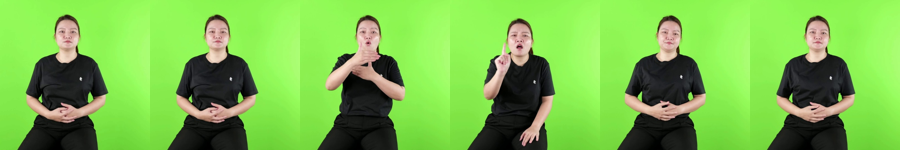


  READING A   Excel row 96
     EN  Is there a patient wellness health program?
     TH  มีโครงการส่งเสริมสุขภาพสำหรับคนไข้ไหม

  READING B   Excel row 95
     EN  Where is the washroom?
     TH  ห้องน้ำอยู่ที่ไหน

VIDEO  b2_B_01_0097    category 1, station B, clip 97


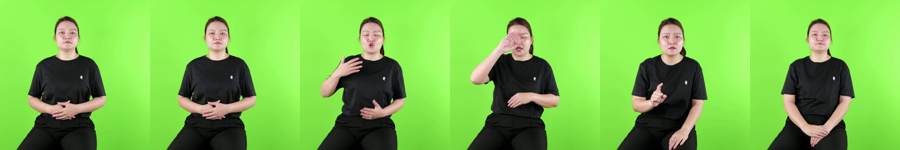


  READING A   Excel row 97
     EN  Can I get a copy of my surgical report?
     TH  ฉันขอสำเนารายงานการผ่าตัดได้ไหม

  READING B   Excel row 96
     EN  Is there a patient wellness health program?
     TH  มีโครงการส่งเสริมสุขภาพสำหรับคนไข้ไหม

VIDEO  b2_B_02_0102    category 2, station B, clip 102


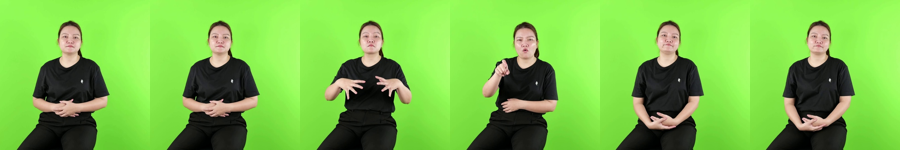


  READING A   Excel row 102
     EN  Get enough rest.
     TH  พักผ่อนให้เพียงพอ

  READING B   Excel row 101
     EN  You need to take a break.
     TH  คุณต้องพักผ่อนบ้าง

VIDEO  b2_B_08_0099    category 8, station B, clip 99


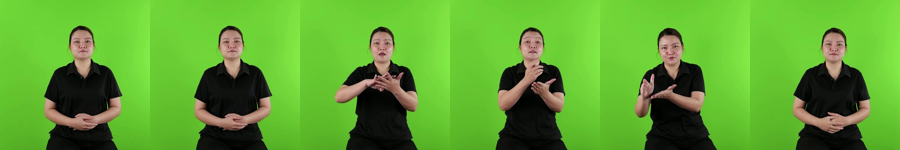


  READING A   Excel row 99
     EN  Home care has a coverage limit.
     TH  การดูแลที่บ้านมีวงเงินความคุ้มครอง

  READING B   Excel row 98
     EN  Payment plans with a grace period.
     TH  มีแผนการชำระเงินพร้อมช่วงผ่อนผัน


In [21]:
# Cell X — parse all 14 spreadsheets, then show the two candidate sentences per video
import re
from IPython.display import display
from PIL import Image

EXCEL_DIR = ARCH / "excel_2ndbatch"
FRAMES    = ARCH / "frames_batch2_30fps"

def catnum(name):
    m = re.match(r"^(\d+)", str(name))
    return int(m.group(1)) if m else None

# ── 1. parse every spreadsheet ──
recs, meta = [], []
for f in sorted(EXCEL_DIR.glob("*.xlsx")):
    raw = pd.read_excel(f, sheet_name=0, header=None)

    hdr = next((i for i in range(min(6, len(raw)))
                if raw.iloc[i].astype(str)
                     .str.contains("text_en", case=False, na=False).any()), None)
    if hdr is None:
        print(f"[SKIP] {f.name}: no text_en header"); continue

    cols = [str(c) for c in raw.iloc[hdr].tolist()]
    body = raw.iloc[hdr+1:].reset_index(drop=True)

    def col_for(pat, fallback):
        for j, c in enumerate(cols):
            if re.search(pat, c, re.I):
                return j
        return fallback
    j_en, j_th = col_for("text_en", 1), col_for("text_th", 2)
    j_st, j_sg = col_for("station", 3), col_for("signer", 4)

    st_txt = body.iloc[:, j_st].dropna()
    st_txt = str(st_txt.iloc[0]).replace("\n", " ") if len(st_txt) else ""
    m = re.search(r"(\d+)", st_txt)
    a_rows = int(m.group(1)) if m else None

    keep = body.iloc[:, [0, j_en, j_th, j_sg]].copy()
    keep.columns = ["excel_id", "text_en", "text_th", "signer"]
    keep = keep[keep[["excel_id", "text_en", "text_th"]].notna().any(axis=1)].reset_index(drop=True)
    keep["row"] = keep.index + 1
    keep["cat"] = catnum(f.name)
    keep["signer"] = keep["signer"].ffill()
    for c in ["text_en", "text_th"]:
        keep[c] = keep[c].fillna("").astype(str).str.strip()

    recs.append(keep)
    meta.append({"cat": catnum(f.name), "file": f.name,
                 "rows": len(keep), "a_rows": a_rows, "station_cell": st_txt})

sent = pd.concat(recs, ignore_index=True)
mt   = pd.DataFrame(meta).sort_values("cat")
sent.to_csv(REPORTS / "batch2_sentences_raw.csv", index=False)

print(mt[["cat","rows","a_rows","station_cell","file"]].to_string(index=False))
print(f"\nTOTAL SENTENCES: {len(sent)}")
print(f"empty Thai: {int((sent['text_th'].str.len()==0).sum())}   "
      f"empty English: {int((sent['text_en'].str.len()==0).sum())}")
print(f"signers seen: {sorted(sent['signer'].dropna().unique())}")
print(f"\nsaved -> {REPORTS / 'batch2_sentences_raw.csv'}")

# ── 2. the alignment question ──
rgb = pd.read_csv(REPORTS / "batch2_rgb.csv")
rgb["cat"] = rgb["category"].map(catnum)
rgb["st"]  = np.where(rgb["station"].str.contains("stationA"), "A", "B")

A_ROWS = dict(zip(mt["cat"], mt["a_rows"]))
CHECK  = [(1, 96), (1, 97), (2, 102), (8, 99)]

def strip(cid, n=6, h=150):
    fs = sorted((FRAMES / cid).glob("*.jpg"))
    if not fs:
        return None
    idx = np.linspace(0, len(fs)-1, n).astype(int)
    out = Image.new("RGB", (h*n, h), "white")
    for k, i in enumerate(idx):
        out.paste(Image.open(fs[i]).resize((h, h)), (k*h, 0))
    return out

for cat, vid in CHECK:
    cid   = f"b2_B_{cat:02d}_{vid:04d}"
    s     = sent[sent["cat"] == cat]
    b_ids = sorted(rgb[(rgb["cat"] == cat) & (rgb["st"] == "B")]["id"].astype(int))

    row_a = vid                                          # reading A: id == row
    row_b = A_ROWS[cat] + 1 + b_ids.index(vid)           # reading B: fill remaining rows in order

    def get(row):
        r = s[s["row"] == row]
        return (r["text_en"].iloc[0], r["text_th"].iloc[0]) if len(r) else ("—", "—")

    enA, thA = get(row_a)
    enB, thB = get(row_b)

    print("\n" + "="*92)
    print(f"VIDEO  {cid}    category {cat}, station B, clip {vid}")
    im = strip(cid)
    if im:
        display(im)
    print(f"\n  READING A   Excel row {row_a}")
    print(f"     EN  {enA}")
    print(f"     TH  {thA}")
    print(f"\n  READING B   Excel row {row_b}")
    print(f"     EN  {enB}")
    print(f"     TH  {thB}")

In [22]:
# the alignment check on its own
rgb = pd.read_csv(REPORTS / "batch2_rgb.csv")
rgb["cat"] = rgb["category"].map(catnum)
rgb["st"]  = np.where(rgb["station"].str.contains("stationA"), "A", "B")
A_ROWS = dict(zip(mt["cat"], mt["a_rows"]))

for cat, vid in [(1, 96), (1, 97), (2, 102), (8, 99)]:
    s     = sent[sent["cat"] == cat]
    b_ids = sorted(rgb[(rgb["cat"] == cat) & (rgb["st"] == "B")]["id"].astype(int))
    row_a = vid
    row_b = A_ROWS[cat] + 1 + b_ids.index(vid)

    def get(row):
        r = s[s["row"] == row]
        return (r["text_en"].iloc[0], r["text_th"].iloc[0]) if len(r) else ("—", "—")

    enA, thA = get(row_a)
    enB, thB = get(row_b)
    print("="*88)
    print(f"category {cat}, station B, clip {vid}   ->   file {vid}-m_*.mp4")
    print(f"  READING A (row {row_a}):  {enA}")
    print(f"                            {thA}")
    print(f"  READING B (row {row_b}):  {enB}")
    print(f"                            {thB}")

category 1, station B, clip 96   ->   file 96-m_*.mp4
  READING A (row 96):  Is there a patient wellness health program?
                            มีโครงการส่งเสริมสุขภาพสำหรับคนไข้ไหม
  READING B (row 95):  Where is the washroom?
                            ห้องน้ำอยู่ที่ไหน
category 1, station B, clip 97   ->   file 97-m_*.mp4
  READING A (row 97):  Can I get a copy of my surgical report?
                            ฉันขอสำเนารายงานการผ่าตัดได้ไหม
  READING B (row 96):  Is there a patient wellness health program?
                            มีโครงการส่งเสริมสุขภาพสำหรับคนไข้ไหม
category 2, station B, clip 102   ->   file 102-m_*.mp4
  READING A (row 102):  Get enough rest.
                            พักผ่อนให้เพียงพอ
  READING B (row 101):  You need to take a break.
                            คุณต้องพักผ่อนบ้าง
category 8, station B, clip 99   ->   file 99-m_*.mp4
  READING A (row 99):  Home care has a coverage limit.
                            การดูแลที่บ้านมีวงเงินความคุ้มครอง

In [24]:
# Cell X3 — decide the alignment by correlating clip duration with sentence length
from scipy.stats import pearsonr, spearmanr

rgb = pd.read_csv(REPORTS / "batch2_rgb.csv")
rgb["cat"] = rgb["category"].map(catnum)
rgb["st"]  = np.where(rgb["station"].str.contains("stationA"), "A", "B")
A_ROWS = dict(zip(mt["cat"], mt["a_rows"]))

def corr(dur, txt):
    if len(dur) < 8:
        return None, None
    return pearsonr(dur, txt)[0], spearmanr(dur, txt)[0]

def lens_for_rows(cat, rows):
    s = sent[sent["cat"] == cat].set_index("row")["text_th"]
    return [len(s[r]) if r in s.index else np.nan for r in rows]

EXACT = [3, 4, 5, 6, 7, 9, 10, 11, 12, 13]
AMBIG = [1, 2, 8]

print("="*92)
print("STEP 1 — does the test work? (categories already known to align exactly)")
print("="*92)
print(f"{'cat':>4} {'n':>5} | {'correct':>16} | {'shifted by 1':>16} | verdict")
print("-"*92)
base = []
for cat in EXACT:
    g = rgb[rgb["cat"] == cat].sort_values("id")
    d = g["duration"].values
    ids = g["id"].astype(int).values
    ok  = lens_for_rows(cat, ids)
    sh  = lens_for_rows(cat, ids - 1)
    m = ~(np.isnan(ok) | np.isnan(sh))
    p_ok, s_ok = corr(d[m], np.array(ok)[m])
    p_sh, s_sh = corr(d[m], np.array(sh)[m])
    base.append(p_ok)
    print(f"{cat:>4} {int(m.sum()):>5} | r={p_ok:6.3f} rho={s_ok:6.3f} | "
          f"r={p_sh:6.3f} rho={s_sh:6.3f} | {'test works' if p_ok > p_sh + 0.1 else 'inconclusive'}")

print(f"\nbaseline correlation when the mapping is CORRECT: mean r = {np.nanmean(base):.3f}")

print("\n" + "="*92)
print("STEP 2 — the ambiguous categories, station B only")
print("="*92)
print(f"{'cat':>4} {'n':>5} | {'READING A':>16} | {'READING B':>16} | winner")
print("-"*92)
for cat in AMBIG:
    g = rgb[(rgb["cat"] == cat) & (rgb["st"] == "B")].sort_values("id")
    d   = g["duration"].values
    ids = g["id"].astype(int).values
    rows_a = ids
    rows_b = np.array([A_ROWS[cat] + 1 + i for i in range(len(ids))])
    la, lb = lens_for_rows(cat, rows_a), lens_for_rows(cat, rows_b)
    m = ~(np.isnan(la) | np.isnan(lb))
    pa, sa = corr(d[m], np.array(la)[m])
    pb, sb = corr(d[m], np.array(lb)[m])
    win = "READING B" if pb > pa else "READING A"
    print(f"{cat:>4} {int(m.sum()):>5} | r={pa:6.3f} rho={sa:6.3f} | "
          f"r={pb:6.3f} rho={sb:6.3f} | {win}")

print("\n" + "="*92)
print("STEP 3 — sanity check on station A of the same categories (mapping is NOT in doubt there)")
print("="*92)
for cat in AMBIG:
    g = rgb[(rgb["cat"] == cat) & (rgb["st"] == "A")].sort_values("id")
    d, ids = g["duration"].values, g["id"].astype(int).values
    ok = lens_for_rows(cat, ids)
    m = ~np.isnan(ok)
    p, s = corr(d[m], np.array(ok)[m])
    print(f"  cat {cat}: n={int(m.sum())}  r={p:.3f}  rho={s:.3f}")

STEP 1 — does the test work? (categories already known to align exactly)
 cat     n |          correct |     shifted by 1 | verdict
--------------------------------------------------------------------------------------------
   3   197 | r= 0.384 rho= 0.422 | r= 0.041 rho=-0.016 | test works
   4   195 | r= 0.632 rho= 0.586 | r= 0.205 rho= 0.170 | test works
   5   198 | r= 0.701 rho= 0.699 | r= 0.533 rho= 0.533 | test works
   6   187 | r= 0.569 rho= 0.588 | r= 0.219 rho= 0.242 | test works
   7   199 | r= 0.572 rho= 0.540 | r= 0.124 rho= 0.117 | test works
   9   197 | r= 0.563 rho= 0.541 | r= 0.010 rho= 0.062 | test works
  10    49 | r= 0.520 rho= 0.618 | r= 0.223 rho= 0.300 | test works
  11    49 | r= 0.460 rho= 0.319 | r=-0.004 rho= 0.029 | test works
  12   201 | r= 0.579 rho= 0.590 | r=-0.111 rho=-0.133 | test works
  13   179 | r= 0.420 rho= 0.490 | r= 0.001 rho= 0.035 | test works

baseline correlation when the mapping is CORRECT: mean r = 0.540

STEP 2 — the ambiguous categ

In [25]:
# Cell X4 — resolve category 14 the same way
g = rgb[(rgb["cat"] == 14) & (rgb["st"] == "B")].sort_values("id")
d, ids = g["duration"].values, g["id"].astype(int).values

cands = {
    "row = id            (100-139)": ids,
    "row = a_rows+1+i    (102-141)": np.array([A_ROWS[14] + 1 + i for i in range(len(ids))]),
}

print("category 14, station B — 40 clips")
print("="*70)
for name, rows in cands.items():
    L = np.array(lens_for_rows(14, rows), dtype=float)
    m = ~np.isnan(L)
    p, s = corr(d[m], L[m])
    print(f"  {name}   n={int(m.sum()):3d}   r={p:6.3f}  rho={s:6.3f}")

gA = rgb[(rgb["cat"] == 14) & (rgb["st"] == "A")].sort_values("id")
LA = np.array(lens_for_rows(14, gA["id"].astype(int).values), dtype=float)
mA = ~np.isnan(LA)
pA, sA = corr(gA["duration"].values[mA], LA[mA])
print(f"\n  station A (row = id, not in doubt)   n={int(mA.sum()):3d}   r={pA:6.3f}  rho={sA:6.3f}")
print("\nwhichever station B candidate is closer to station A's value is the right one.")

category 14, station B — 40 clips
  row = id            (100-139)   n= 40   r= 0.600  rho= 0.525
  row = a_rows+1+i    (102-141)   n= 40   r= 0.003  rho= 0.071

  station A (row = id, not in doubt)   n= 40   r= 0.415  rho= 0.426

whichever station B candidate is closer to station A's value is the right one.


In [30]:
# Cell S — full statistics for both batches -> CSV
import re
from pathlib import Path
import numpy as np, pandas as pd

HOME    = Path.home()
ARCH    = HOME / "dataset_arch" / "SignLanguage"
REPORTS = HOME / "work" / "signlanguage" / "reports"

FRAMES_B2 = ARCH / "frames_batch2_30fps"
SPAT_B2   = ARCH / "features_b2_30fps" / "spatial"
MOT_B2    = ARCH / "features_b2_30fps" / "motion"
FRAMES_B1 = ARCH / "frames"

def catnum(s):
    m = re.match(r"^(\d+)", str(s))
    return int(m.group(1)) if m else None

# ══════════════════════════════════════════════════════════════════
# BATCH 2
# ══════════════════════════════════════════════════════════════════
rgb  = pd.read_csv(REPORTS / "batch2_rgb.csv")
sent2 = pd.read_csv(REPORTS / "batch2_sentences_raw.csv")

rgb["cat"]     = rgb["category"].map(catnum)
rgb["station"] = np.where(rgb["station"].str.contains("stationA"), "A", "B")
rgb["id"]      = rgb["id"].astype(int)

A_ROWS = {1:94, 2:100, 3:99, 4:98, 5:100, 6:94, 7:100, 8:97,
          9:99, 10:25, 11:25, 12:101, 13:90, 14:101}
SHIFT_CATS = {1, 2, 8}                      # verified by the duration/length test

rows = []
for cat, g in rgb.groupby("cat"):
    b_ids = sorted(g.loc[g["station"] == "B", "id"])
    for _, r in g.iterrows():
        if r["station"] == "A" or cat not in SHIFT_CATS:
            row = r["id"]
        else:
            row = A_ROWS[cat] + 1 + b_ids.index(r["id"])
        rows.append({"cat": cat, "station": r["station"], "id": r["id"], "excel_row": row})
map2 = pd.DataFrame(rows)

b2 = (rgb.merge(map2, on=["cat","station","id"], how="left")
         .merge(sent2[["cat","row","text_en","text_th","signer"]],
                left_on=["cat","excel_row"], right_on=["cat","row"], how="left"))

b2["clip_id"]   = b2.apply(lambda r: f"b2_{r['station']}_{int(r['cat']):02d}_{int(r['id']):04d}", axis=1)
b2["batch"]     = "batch2"
b2["domain"]    = "medical"
b2["cat_name"]  = b2["category"]
b2["stride"]    = (b2["fps"] / 30).round().astype(int)
b2["frames_30"] = (b2["nb_frames"] / b2["stride"]).round()
b2["include"]   = True
b2["exclude_reason"] = ""

# ══════════════════════════════════════════════════════════════════
# BATCH 1
# ══════════════════════════════════════════════════════════════════
b1p   = pd.read_csv(REPORTS / "batch1_fps.csv")
b1f   = pd.read_csv(REPORTS / "batch1_frames.csv")
sent1 = pd.read_csv(REPORTS / "batch1_sentences_raw.csv")

b1f = b1f[b1f["clip"] != ".ipynb_checkpoints"].copy()
b1f["clipnum"]  = b1f["clip"].str.extract(r"_clip_(\d+)$").astype(int)
b1f["cat_name"] = b1f["category"]

b1 = (b1p.rename(columns={"cat":"cat_name", "clip":"clipnum"})
         .merge(b1f[["cat_name","clipnum","n_frames","bytes"]], on=["cat_name","clipnum"], how="outer")
         .merge(sent1[["folder","clip_num","text_th","signer"]].rename(
                    columns={"folder":"cat_name", "clip_num":"clipnum"}),
                on=["cat_name","clipnum"], how="left"))

b1["clip_id"]   = b1.apply(lambda r: f"b1_{r['cat_name']}_{int(r['clipnum']):04d}", axis=1)
b1["batch"]     = "batch1"
b1["domain"]    = "cooking"
b1["cat"]       = b1["cat_name"].map(catnum)
b1["station"]   = "-"
b1["id"]        = b1["clipnum"]
b1["excel_row"] = b1["clipnum"]
b1["duration"]  = b1["seconds"]
b1["nb_frames"] = b1["bag_frames"]
b1["png_frames"]= b1["n_frames"]
b1["frames_30"] = (b1["seconds"] * 30).round()
b1["w"], b1["h"], b1["codec"] = 1920, 1080, "png"
b1["text_en"]   = np.nan                    # batch 1 has no English
b1["include"]   = b1["fps"] >= 20
b1["exclude_reason"] = np.where(b1["fps"] < 20, "recorded below 20 fps", "")
b1["frames_match"]   = b1["png_frames"] == b1["bag_frames"]

# ══════════════════════════════════════════════════════════════════
# what exists on disk
# ══════════════════════════════════════════════════════════════════
fd2  = {p.name for p in FRAMES_B2.iterdir() if p.is_dir()}
sp2  = {p.name.replace("_s2wrapping.npy","") for p in SPAT_B2.glob("*.npy")}
mo2  = {p.name.replace("_overlap-8.npy","")  for p in MOT_B2.glob("*.npy")}

b2["frames_ok"]  = b2["clip_id"].isin(fd2)
b2["spatial_ok"] = b2["clip_id"].isin(sp2)
b2["motion_ok"]  = b2["clip_id"].isin(mo2)

b1["frames_ok"]  = b1["png_frames"].fillna(0) > 0       # original PNGs, not yet 30 fps
b1["spatial_ok"] = False
b1["motion_ok"]  = False

# ══════════════════════════════════════════════════════════════════
# MASTER TABLE
# ══════════════════════════════════════════════════════════════════
COLS = ["clip_id","batch","domain","cat","cat_name","station","id","excel_row","signer",
        "fps","duration","nb_frames","stride","frames_30","w","h","codec",
        "frames_ok","spatial_ok","motion_ok","text_th","text_en",
        "include","exclude_reason"]
for c in COLS:
    for d in (b1, b2):
        if c not in d.columns:
            d[c] = np.nan

master = pd.concat([b2[COLS], b1[COLS]], ignore_index=True)
master["thai_len"] = master["text_th"].fillna("").astype(str).str.len().replace(0, np.nan)
master["en_len"]   = master["text_en"].fillna("").astype(str).str.len().replace(0, np.nan)
master["has_thai"] = master["thai_len"].notna()
master["has_en"]   = master["en_len"].notna()
master = master.sort_values(["batch","cat","station","id"]).reset_index(drop=True)
master.to_csv(REPORTS / "master_clips.csv", index=False)

# ══════════════════════════════════════════════════════════════════
# SUMMARIES
# ══════════════════════════════════════════════════════════════════
bycat = (master.groupby(["batch","domain","cat","cat_name","station"], dropna=False)
         .agg(clips=("clip_id","count"),
              fps_min=("fps","min"), fps_med=("fps","median"), fps_max=("fps","max"),
              dur_total_s=("duration","sum"), dur_mean_s=("duration","mean"),
              dur_min_s=("duration","min"), dur_max_s=("duration","max"),
              src_frames=("nb_frames","sum"), frames_at_30=("frames_30","sum"),
              frames_ok=("frames_ok","sum"), spatial_ok=("spatial_ok","sum"),
              motion_ok=("motion_ok","sum"),
              with_thai=("has_thai","sum"), with_en=("has_en","sum"),
              thai_len_mean=("thai_len","mean"), thai_len_max=("thai_len","max"),
              usable=("include","sum"))
         .round(2).reset_index())
bycat.to_csv(REPORTS / "stats_by_category.csv", index=False)

def block(d, label):
    return {"scope": label, "clips": len(d),
            "usable": int(d["include"].sum()),
            "signing_hours": round(d["duration"].sum()/3600, 2),
            "dur_mean_s": round(d["duration"].mean(), 2),
            "dur_min_s": round(d["duration"].min(), 2),
            "dur_max_s": round(d["duration"].max(), 2),
            "fps_min": round(d["fps"].min(), 1),
            "fps_median": round(d["fps"].median(), 1),
            "fps_max": round(d["fps"].max(), 1),
            "source_frames": int(d["nb_frames"].sum()),
            "frames_at_30fps": int(d["frames_30"].sum()),
            "frames_on_disk": int(d["frames_ok"].sum()),
            "spatial_features": int(d["spatial_ok"].sum()),
            "motion_features": int(d["motion_ok"].sum()),
            "with_thai": int(d["has_thai"].sum()),
            "without_thai": int((~d["has_thai"]).sum()),
            "with_english": int(d["has_en"].sum()),
            "thai_len_mean": round(d["thai_len"].mean(), 1) if d["thai_len"].notna().any() else None,
            "thai_len_max": int(d["thai_len"].max()) if d["thai_len"].notna().any() else None,
            "signers": ", ".join(sorted(d["signer"].dropna().astype(str).str.lower().unique()))}

summary = pd.DataFrame([
    block(master[master["batch"]=="batch1"], "batch1 (cooking)"),
    block(master[master["batch"]=="batch2"], "batch2 (medical)"),
    block(master, "combined"),
    block(master[master["include"]], "combined, usable only"),
])
summary.to_csv(REPORTS / "stats_summary.csv", index=False)

# ── problems ──
probs = []
for _, r in master.iterrows():
    iss = []
    if not r["frames_ok"]:  iss.append("no frames on disk")
    if not r["has_thai"]:   iss.append("NO THAI SENTENCE")
    if r["batch"] == "batch2" and not r["spatial_ok"]: iss.append("no spatial features")
    if r["batch"] == "batch2" and not r["motion_ok"]:  iss.append("no motion features")
    if not r["include"]:    iss.append(str(r["exclude_reason"]))
    if iss:
        probs.append({"clip_id": r["clip_id"], "batch": r["batch"],
                      "cat_name": r["cat_name"], "fps": r["fps"], "issues": "; ".join(iss)})
problems = pd.DataFrame(probs)
problems.to_csv(REPORTS / "clip_problems.csv", index=False)

# ── sentences never filmed ──
unf = []
for cat, g in sent2.groupby("cat"):
    used = set(map2.loc[map2["cat"] == cat, "excel_row"])
    for _, r in g[~g["row"].isin(used)].iterrows():
        unf.append({"batch":"batch2","group":cat,"row":r["row"],
                    "text_th":r["text_th"],"text_en":r["text_en"]})
b1_used = set(zip(b1["cat_name"], b1["clipnum"]))
for _, r in sent1.iterrows():
    if (r["folder"], r["clip_num"]) not in b1_used:
        unf.append({"batch":"batch1","group":r["episode"],"row":r["clip_num"],
                    "text_th":r["text_th"],"text_en":None})
unfilmed = pd.DataFrame(unf)
unfilmed.to_csv(REPORTS / "sentences_never_filmed.csv", index=False)

# ══════════════════════════════════════════════════════════════════
print("="*96); print("SUMMARY"); print("="*96)
print(summary.set_index("scope").T.to_string())

print("\n" + "="*96); print("BATCH 2 BY CATEGORY"); print("="*96)
print(bycat[bycat["batch"]=="batch2"][
  ["cat","station","clips","fps_med","dur_mean_s","frames_at_30","with_thai","with_en","thai_len_mean"]
].to_string(index=False))

print("\n" + "="*96); print("BATCH 1 BY EPISODE"); print("="*96)
print(bycat[bycat["batch"]=="batch1"][
  ["cat_name","clips","fps_min","fps_med","fps_max","dur_mean_s","frames_at_30","with_thai","usable"]
].to_string(index=False))

print("\n" + "="*96); print("PROBLEMS"); print("="*96)
print(f"clips with any issue: {len(problems)}")
if len(problems):
    print(problems["issues"].value_counts().to_string())
print(f"\nsentences never filmed: {len(unfilmed)}")
if len(unfilmed):
    print(unfilmed.groupby(["batch","group"]).size().to_string())
bad = b1[b1["frames_match"] == False]
print(f"\nbatch 1 clips where PNG count != source count: {len(bad)}")

print("\n" + "="*96); print("FILES WRITTEN"); print("="*96)
for f in ["master_clips.csv","stats_by_category.csv","stats_summary.csv",
          "clip_problems.csv","sentences_never_filmed.csv"]:
    print(f"  {f:34s} {(REPORTS/f).stat().st_size/1e3:8.1f} KB")

SUMMARY
scope                    batch1 (cooking)          batch2 (medical)                         combined            combined, usable only
clips                                1053                      2320                             3373                             3333
usable                               1013                      2320                             3333                             3333
signing_hours                        3.66                      5.75                             9.42                             9.28
dur_mean_s                          12.53                      8.93                            10.05                            10.02
dur_min_s                            5.76                      3.73                             3.73                             3.73
dur_max_s                           34.54                      22.7                            34.54                            34.54
fps_min                              12.6             

In [37]:
# Cell T5 — normalise signer names, then re-save master_clips.csv
m = pd.read_csv(REPORTS / "master_clips.csv")

FIX = {"totak": "toktak", "ต๊อกแต๊ก": "toktak", "ไกด์": "guide"}

s = m["signer"].astype(str).str.strip().str.lower()
s = s.replace(FIX)
s = s.replace({"nan": np.nan, "none": np.nan, "": np.nan})
m["signer"] = s
m["signer_known"] = m["signer"].notna()
m["signer"] = m["signer"].fillna("unknown")

m.to_csv(REPORTS / "master_clips.csv", index=False)

print("="*70); print("SIGNERS AFTER NORMALISING"); print("="*70)
out = (m.groupby("signer")
         .agg(clips=("clip_id","count"),
              hours=("duration", lambda x: round(x.sum()/3600, 2)))
         .reset_index().sort_values("hours", ascending=False))
out["share_%"] = (100*out["hours"]/out["hours"].sum()).round(1)
print(out.to_string(index=False))

print(f"\n  total hours  {out['hours'].sum():.2f} ")
print(f"  total clips  {int(out['clips'].sum())} ")

print("\n" + "="*70); print("SIGNER BY BATCH"); print("="*70)
print(pd.crosstab(m["signer"], m["batch"], margins=True).to_string())

print("\n" + "="*70); print("WHICH EPISODES HAVE NO SIGNER RECORDED"); print("="*70)
unk = m[m["signer"] == "unknown"]
print(f"{len(unk)} clips, {unk['duration'].sum()/3600:.2f} hours")
if len(unk):
    print(unk.groupby(["batch","cat_name"]).agg(
        clips=("clip_id","count"),
        hours=("duration", lambda x: round(x.sum()/3600, 2))).to_string())

SIGNERS AFTER NORMALISING
 signer  clips  hours  share_%
unknown    637   2.33     24.7
   dear    733   1.96     20.8
  guide    681   1.81     19.2
    gig    684   1.73     18.4
 toktak    638   1.59     16.9

  total hours  9.42   (must be 9.42)
  total clips  3373   (must be 3373)

SIGNER BY BATCH
batch    batch1  batch2   All
signer                       
dear        133     600   733
gig          84     600   684
guide       120     561   681
toktak       79     559   638
unknown     637       0   637
All        1053    2320  3373

WHICH EPISODES HAVE NO SIGNER RECORDED
637 clips, 2.33 hours
                               clips  hours
batch  cat_name                            
batch1 3_molecular_gastronomy    130   0.48
       4_steak                   164   0.54
       5_chanthaburi_seafood      70   0.23
       6_leaf                    154   0.60
       8_chicken                 119   0.47


In [38]:
# did sheet 4 actually have signer info?
XL = HOME / "work" / "tsl" / "แบ่งประโยค cook culture (aitsign7@gmail.com).xlsx"
raw = pd.read_excel(XL, sheet_name="4 เนื้อนี้อยู่น่าน", header=None)
for j in range(raw.shape[1]):
    vals = raw.iloc[2:, j].dropna().astype(str).str.strip()
    print(f"col {j}: {len(vals)} non-empty   unique: {sorted(vals.unique())[:8]}")

col 0: 165 non-empty   unique: ['1', '10', '100', '101', '102', '103', '104', '105']
col 1: 165 non-empty   unique: ['2 เราได้เนื้อคุณภาพดีๆ ที่ไว้ใจได้ ทุกกระบวนทุกขั้นตอน เราสามารถบอกได้เลยว่า เนื้อมาจากไหน ซึ่งตรงเนี้ย มันมีผลกับผู้บริโภคโดยตรง', 'กลิ่นหม่อน แล้วก็มีมะแขว่นแทรกค่ะ ตัวนี้', 'การหมักเนี่ย ของเมย์ก็จะมีแค่เกลือ พริกไทย', 'การเลี้ยงโคเนื้อมันเป็นอะไรที่ยาว วัวเนี่ย ต้องใช้เวลา 2-4 ปี หรือมากกว่าอะไรเงี้ย เป็นต้น', 'ก็คือกิน กินข้าวโพดหมักที่เรามีที่น่านอะไรอย่างเงี้ยครับ แล้วก็ใส่อาหารเข้าไป', 'ก็จะมี 2 ซอสให้เลือก แล้วแต่ลูกค้าชอบว่าอยากจะกินซอสไหน', 'ก็ถือว่าเป็น เป็นเรื่องที่ดี ในการที่จะเตรียมความพร้อม ในการที่จะรองรับความเจริญเติบโต ในเรื่องของการท่องเที่ยวจังหวัดน่านนะครับ', 'ก็พลิกไปพลิกมาค่ะ ประมาณ 2 รอบ']
col 2: 0 non-empty   unique: []
col 3: 10 non-empty   unique: ['gig', 'toatak']


In [39]:
# Cell F1 — re-extract batch 1 signers with a wider known-name list
import re
XL = HOME / "work" / "tsl" / "แบ่งประโยค cook culture (aitsign7@gmail.com).xlsx"

SHEET_TO_FOLDER = {1:"1_worldcooking", 2:"2_salt", 3:"3_molecular_gastronomy",
                   4:"4_steak", 5:"5_chanthaburi_seafood", 6:"6_leaf",
                   7:None, 8:"8_chicken", 9:None, 10:None}

KNOWN = {"dear","guide","gig","totak","toktak","toatak","ต๊อกแต๊ก","ไกด์"}
NORM  = {"totak":"toktak", "toatak":"toktak", "ต๊อกแต๊ก":"toktak", "ไกด์":"guide"}

rows = []
for sh in pd.ExcelFile(XL).sheet_names:
    m = re.match(r"^\s*(\d+)", sh)
    if not m:
        continue
    ep, folder = int(m.group(1)), SHEET_TO_FOLDER.get(int(m.group(1)))
    raw  = pd.read_excel(XL, sheet_name=sh, header=None)
    hdr  = [str(x) for x in raw.iloc[1].tolist()]
    body = raw.iloc[2:].reset_index(drop=True)

    # find the signer column
    j_sg = next((j for j, h in enumerate(hdr) if "signer" in h.lower()), None)
    if j_sg is None:
        for j in range(body.shape[1]):
            v = body.iloc[:, j].dropna().astype(str).str.strip().str.lower()
            if len(v) and v.isin(KNOWN).mean() > 0.5:
                j_sg = j; break

    print(f"ep {ep:>2} {str(folder):24s} signer col = {j_sg}", end="")
    if j_sg is not None:
        seen = body.iloc[:, j_sg].dropna().astype(str).str.strip().str.lower().unique()
        print(f"   values: {sorted(seen)}")
    else:
        print("   NO SIGNER COLUMN")

    # walk rows, carrying the signer forward
    cur, last = None, None
    for _, r in body.iterrows():
        cn = pd.to_numeric(r.iloc[0], errors="coerce")
        if pd.notna(cn):
            cur = int(cn)
        sg = None
        if j_sg is not None and pd.notna(r.iloc[j_sg]):
            sg = str(r.iloc[j_sg]).strip().lower()
            sg = NORM.get(sg, sg)
            if sg in {NORM.get(k, k) for k in KNOWN}:
                last = sg
        if cur is not None and folder:
            rows.append({"cat_name": folder, "clipnum": cur, "signer_fixed": last})

sg1 = pd.DataFrame(rows).drop_duplicates(["cat_name","clipnum"], keep="first")
sg1.to_csv(REPORTS / "batch1_signers_fixed.csv", index=False)
print(f"\n{len(sg1)} clips, signer known for {int(sg1['signer_fixed'].notna().sum())}")
print(sg1["signer_fixed"].value_counts(dropna=False).to_string())

ep  1 1_worldcooking           signer col = 2   values: ['dear', 'guide']
ep  2 2_salt                   signer col = 2   values: ['gig', 'totak']
ep  3 3_molecular_gastronomy   signer col = None   NO SIGNER COLUMN
ep  4 4_steak                  signer col = 3   values: ['gig', 'toatak']
ep  5 5_chanthaburi_seafood    signer col = None   NO SIGNER COLUMN
ep  6 6_leaf                   signer col = None   NO SIGNER COLUMN
ep  7 None                     signer col = None   NO SIGNER COLUMN
ep  8 8_chicken                signer col = None   NO SIGNER COLUMN
ep  9 None                     signer col = None   NO SIGNER COLUMN
ep 10 None                     signer col = None   NO SIGNER COLUMN

1159 clips, signer known for 581
signer_fixed
None      578
toktak    194
gig       134
dear      133
guide     120


In [40]:
# Cell F2 — apply the signer fix, then write ONE overview CSV
m   = pd.read_csv(REPORTS / "master_clips.csv")
sg1 = pd.read_csv(REPORTS / "batch1_signers_fixed.csv")

m["clipnum"] = m["id"]
m = m.merge(sg1, on=["cat_name","clipnum"], how="left")

NORM = {"totak":"toktak", "toatak":"toktak", "dear":"dear",
        "guide":"guide", "gig":"gig", "toktak":"toktak"}
s = m["signer"].astype(str).str.strip().str.lower().replace(NORM)
s = s.where(~s.isin(["nan","none","unknown",""]), np.nan)
s = s.fillna(m["signer_fixed"].astype(str).str.lower().replace(NORM))
s = s.where(~s.isin(["nan","none",""]), np.nan)
m["signer"] = s.fillna("unknown")
m = m.drop(columns=["clipnum","signer_fixed"])
m.to_csv(REPORTS / "master_clips.csv", index=False)

print("signers now:")
print(m.groupby("signer").agg(clips=("clip_id","count"),
      hours=("duration", lambda x: round(x.sum()/3600,2))).to_string())

# ── ONE CSV for sharing ──
def agg(d, level, batch="", domain="", cat="", station=""):
    return {
        "level": level, "batch": batch, "domain": domain,
        "category": cat, "station": station,
        "clips": len(d),
        "clips_usable": int(d["include"].sum()),
        "clips_excluded": int((~d["include"]).sum()),
        "total_seconds": round(d["duration"].sum(), 1),
        "total_minutes": round(d["duration"].sum()/60, 2),
        "total_hours": round(d["duration"].sum()/3600, 3),
        "clip_mean_s": round(d["duration"].mean(), 2),
        "clip_min_s": round(d["duration"].min(), 2),
        "clip_max_s": round(d["duration"].max(), 2),
        "fps_min": round(d["fps"].min(), 1),
        "fps_median": round(d["fps"].median(), 1),
        "fps_max": round(d["fps"].max(), 1),
        "source_frames": int(d["nb_frames"].sum()),
        "frames_at_30fps": int(d["frames_30"].sum()),
        "frames_on_disk": int(d["frames_ok"].sum()),
        "spatial_features": int(d["spatial_ok"].sum()),
        "motion_features": int(d["motion_ok"].sum()),
        "with_thai": int(d["has_thai"].sum()),
        "with_english": int(d["has_en"].sum()),
        "thai_chars_mean": round(d["thai_len"].mean(), 1),
        "thai_chars_max": int(d["thai_len"].max()) if d["thai_len"].notna().any() else None,
        "signers": ", ".join(sorted(d["signer"].dropna().unique())),
    }

out = [agg(m, "TOTAL (both batches)")]
for b, g in m.groupby("batch"):
    out.append(agg(g, "batch total", batch=b, domain=g["domain"].iloc[0]))
for (b, cn, st), g in m.groupby(["batch","cat_name","station"], dropna=False):
    out.append(agg(g, "category", batch=b, domain=g["domain"].iloc[0],
                   cat=cn, station=st))

ov = pd.DataFrame(out)
order = {"TOTAL (both batches)": 0, "batch total": 1, "category": 2}
ov = ov.sort_values(["level","batch","category","station"],
                    key=lambda c: c.map(order) if c.name == "level" else c)
ov.to_csv(REPORTS / "TSL_dataset_overview.csv", index=False)

print(f"\n{len(ov)} rows -> {REPORTS / 'TSL_dataset_overview.csv'}")
print(ov[["level","batch","category","station","clips","clips_usable",
          "total_hours","clip_mean_s","fps_median","with_thai","with_english"]]
      .to_string(index=False))

signers now:
         clips  hours
signer               
dear       733   1.96
gig        734   1.87
guide      681   1.81
toktak     752   1.99
unknown    473   1.79

38 rows -> /home/soehn/work/signlanguage/reports/TSL_dataset_overview.csv
               level  batch                       category station  clips  clips_usable  total_hours  clip_mean_s  fps_median  with_thai  with_english
TOTAL (both batches)                                                 3373          3333        9.416        10.05        66.0       3373          2320
         batch total batch1                                          1053          1013        3.664        12.53        57.7       1053             0
         batch total batch2                                          2320          2320        5.752         8.93       120.0       2320          2320
            category batch1                 1_worldcooking       -    253           253        0.734        10.45        39.6        253             0
   

In [42]:
# Cell F3 — clean category names, rewrite the overview
CANON_B2 = {1:"general_hospital", 2:"doctor_patient", 3:"medical_history",
            4:"treatment_and_diagnosis", 5:"medical_emergencies",
            6:"common_symptoms", 7:"questions_from_patients",
            8:"admin_and_billing", 9:"prescription", 10:"nutrition_and_diet",
            11:"travel_medicine", 12:"mental_health", 13:"infectious_disease",
            14:"pharmacy"}
CANON_B1 = {1:"worldcooking", 2:"salt", 3:"molecular_gastronomy", 4:"steak",
            5:"chanthaburi_seafood", 6:"leaf", 8:"chicken"}

m = pd.read_csv(REPORTS / "master_clips.csv")
m["category_clean"] = [
    (CANON_B2 if b == "batch2" else CANON_B1).get(int(c), str(n))
    for b, c, n in zip(m["batch"], m["cat"], m["cat_name"])
]
m.to_csv(REPORTS / "master_clips.csv", index=False)

out = [agg(m, "TOTAL (both batches)")]
for b, g in m.groupby("batch"):
    out.append(agg(g, "batch total", batch=b, domain=g["domain"].iloc[0]))
for (b, cnum, cclean, st), g in m.groupby(["batch","cat","category_clean","station"],
                                          dropna=False):
    out.append(agg(g, "category", batch=b, domain=g["domain"].iloc[0],
                   cat=f"{int(cnum):02d} {cclean}", station=st))

ov = pd.DataFrame(out)
order = {"TOTAL (both batches)":0, "batch total":1, "category":2}
ov = ov.sort_values(["level","batch","category","station"],
                    key=lambda c: c.map(order) if c.name == "level" else c)
ov.to_csv(REPORTS / "TSL_dataset_overview.csv", index=False)

print(f"{len(ov)} rows -> {REPORTS / 'TSL_dataset_overview.csv'}")
print(ov[["level","batch","category","station","clips","clips_usable",
          "total_hours","clip_mean_s","fps_median","with_english"]].to_string(index=False))

38 rows -> /home/soehn/work/signlanguage/reports/TSL_dataset_overview.csv
               level  batch                   category station  clips  clips_usable  total_hours  clip_mean_s  fps_median  with_english
TOTAL (both batches)                                             3373          3333        9.416        10.05        66.0          2320
         batch total batch1                                      1053          1013        3.664        12.53        57.7             0
         batch total batch2                                      2320          2320        5.752         8.93       120.0          2320
            category batch1            01 worldcooking       -    253           253        0.734        10.45        39.6             0
            category batch1                    02 salt       -    163           163        0.599        13.22        64.4             0
            category batch1    03 molecular_gastronomy       -    130           130        0.485        13.42 

In [27]:
# Cell B1-excel — find and preview the batch 1 spreadsheet
from pathlib import Path
import pandas as pd

HOME = Path.home()
ARCH = HOME / "dataset_arch" / "SignLanguage"

# it may still be in work/tsl, or already moved to 1st_batch
candidates = list((ARCH / "1st_batch").glob("*.xls*")) + \
             list((HOME / "work" / "tsl").glob("*.xls*")) + \
             list(ARCH.glob("*.xls*"))
candidates = [p for p in candidates if not p.name.startswith("~$")]

print(f"{len(candidates)} spreadsheet(s) found:")
for p in candidates:
    print(f"   {p}   ({p.stat().st_size/1e3:.0f} KB)")

if not candidates:
    print("\nNot found. Locate it with:")
    print('   find ~/dataset_arch ~/work -maxdepth 3 -name "*.xlsx" -not -name "~\\$*" 2>/dev/null')
else:
    f = candidates[0]
    xl = pd.ExcelFile(f)
    print(f"\n{'='*84}")
    print(f"FILE   : {f.name}")
    print(f"SHEETS ({len(xl.sheet_names)}):")
    for sh in xl.sheet_names:
        d = pd.read_excel(f, sheet_name=sh, header=None)
        print(f"   {sh!r:44s} shape {d.shape}")

    for sh in xl.sheet_names:
        d = pd.read_excel(f, sheet_name=sh, header=None)
        print(f"\n{'='*84}")
        print(f"SHEET {sh!r}   shape {d.shape}")
        print(d.head(10).to_string(max_colwidth=42))

1 spreadsheet(s) found:
   /home/soehn/work/tsl/แบ่งประโยค cook culture (aitsign7@gmail.com).xlsx   (352 KB)

FILE   : แบ่งประโยค cook culture (aitsign7@gmail.com).xlsx
SHEETS (12):
   '1 ไส้อั่ว ไกด์'                             shape (314, 4)
   '2 เค็ม ต๊อกแต๊ก'                            shape (165, 4)
   '3 เทคนิค'                                   shape (133, 2)
   '4 เนื้อนี้อยู่น่าน'                         shape (167, 4)
   '5 เมนูจากทะเลเมืองจันท์'                    shape (148, 2)
   '6 กระวาน'                                   shape (156, 2)
   '7 ปลาร้า'                                   shape (179, 6)
   '8 ไก่'                                      shape (150, 2)
   '9 ไข่ไก่อารมณ์ดี'                           shape (141, 2)
   '10 พริกแกงพร้อมปรุง'                        shape (110, 2)
   'คำศัพท์1'                                   shape (52, 2)
   'คำศัพท์2'                                   shape (155, 1)

SHEET '1 ไส้อั่ว ไกด์'   shape (314, 4)
        0             

In [31]:
# Cell T3 — flexible duration report
master = pd.read_csv(REPORTS / "master_clips.csv")

def hms(sec):
    h, rem = divmod(int(round(float(sec))), 3600)
    m, s = divmod(rem, 60)
    return f"{h}h {m:02d}m {s:02d}s"

def total(batch=None, cat=None, station=None, signer=None,
          fps_min=None, fps_max=None, usable_only=False,
          group_by=None, label=None):
    """Total clip length for any subset. All arguments optional."""
    d = master.copy()
    applied = []

    if batch:        d = d[d["batch"].isin(np.atleast_1d(batch))];        applied.append(f"batch={batch}")
    if cat:          d = d[d["cat"].isin(np.atleast_1d(cat))];            applied.append(f"cat={cat}")
    if station:      d = d[d["station"].isin(np.atleast_1d(station))];    applied.append(f"station={station}")
    if signer:       d = d[d["signer"].isin(np.atleast_1d(signer))];      applied.append(f"signer={signer}")
    if fps_min is not None: d = d[d["fps"] >= fps_min];                   applied.append(f"fps>={fps_min}")
    if fps_max is not None: d = d[d["fps"] <= fps_max];                   applied.append(f"fps<={fps_max}")
    if usable_only:  d = d[d["include"]];                                 applied.append("usable only")

    head = label or (" , ".join(applied) if applied else "everything")
    print(f"\n{'='*74}")
    print(f"{head}")
    print(f"{'='*74}")
    if not len(d):
        print("  no clips match"); return d

    print(f"  clips        {len(d):>6}")
    print(f"  total length {hms(d['duration'].sum()):>14}   ({d['duration'].sum()/3600:.2f} hours)")
    print(f"  mean / min / max   {d['duration'].mean():.1f}s / "
          f"{d['duration'].min():.1f}s / {d['duration'].max():.1f}s")
    print(f"  fps  min / median / max   {d['fps'].min():.1f} / "
          f"{d['fps'].median():.1f} / {d['fps'].max():.1f}")
    print(f"  frames at 30 fps  {int(d['frames_30'].sum()):>10,}")
    print(f"  with Thai {int(d['has_thai'].sum())} , with English {int(d['has_en'].sum())}")

    if group_by:
        g = (d.groupby(group_by, dropna=False)
               .agg(clips=("clip_id","count"), secs=("duration","sum"),
                    mean_s=("duration","mean"), fps_med=("fps","median"))
               .reset_index())
        g["length"] = g["secs"].map(hms)
        g["hours"]  = (g["secs"]/3600).round(2)
        g["share_%"] = (100*g["secs"]/d["duration"].sum()).round(1)
        print()
        print(g[np.atleast_1d(group_by).tolist() +
                ["clips","length","hours","mean_s","fps_med","share_%"]]
              .round(2).to_string(index=False))
    return d

In [32]:
# everything
total(label="ALL CLIPS")

# only what will actually be trained on
total(usable_only=True, group_by="batch", label="USABLE ONLY, split by batch")

# one batch, broken down by category
total(batch="batch2", group_by=["cat","station"], label="BATCH 2 by category and station")
total(batch="batch1", group_by="cat_name",       label="BATCH 1 by episode")

# by frame rate
total(fps_min=100,            label="120 fps clips only")
total(fps_min=50, fps_max=75, label="60-75 fps clips")
total(fps_max=20,             label="the excluded low-fps clips")

# by signer
total(group_by="signer", label="ALL, split by signer")
total(signer="dear", group_by="batch", label="signer 'dear' only")

# a single category
total(cat=6, group_by=["batch","station"], label="category / episode 6")

# combinations
total(batch="batch2", station="A", fps_min=100, label="batch 2, station A, 120 fps")


ALL CLIPS
  clips          3373
  total length     9h 24m 57s   (9.42 hours)
  mean / min / max   10.0s / 3.7s / 34.5s
  fps  min / median / max   12.6 / 66.0 / 120.0
  frames at 30 fps   1,016,952
  with Thai 3373 , with English 2320

USABLE ONLY, split by batch
  clips          3333
  total length     9h 16m 52s   (9.28 hours)
  mean / min / max   10.0s / 3.7s / 34.5s
  fps  min / median / max   29.0 / 66.2 / 120.0
  frames at 30 fps   1,002,397
  with Thai 3333 , with English 2320

 batch  clips     length  hours  mean_s  fps_med  share_%
batch1   1013 3h 31m 46s   3.53   12.54     62.1     38.0
batch2   2320 5h 45m 06s   5.75    8.93    120.0     62.0

BATCH 2 by category and station
  clips          2320
  total length     5h 45m 06s   (5.75 hours)
  mean / min / max   8.9s / 3.7s / 22.7s
  fps  min / median / max   60.0 / 120.0 / 120.0
  frames at 30 fps     621,202
  with Thai 2320 , with English 2320

 cat station  clips     length  hours  mean_s  fps_med  share_%
   1       A

,clip_id,batch,domain,cat,cat_name,station,id,excel_row,signer,fps,...,spatial_ok,motion_ok,text_th,text_en,include,exclude_reason,thai_len,en_len,has_thai,has_en
1439,b2_A_03_0001,batch2,medical,3,3_medical_history,A,1,1,Dear,120.0,...,True,True,มีโรคประจำตัวไหม,Do you have any chronic illnesses?,True,NaN,16,34.0,True,True
1440,b2_A_03_0002,batch2,medical,3,3_medical_history,A,2,2,Dear,120.0,...,True,True,คุณเคยเข้ารักษาตัวในโรงพยาบาลไหม,Have you ever been hospitalized?,True,NaN,32,32.0,True,True
1441,b2_A_03_0003,batch2,medical,3,3_medical_history,A,3,3,Dear,120.0,...,True,True,คุณตรวจสุขภาพครั้งล่าสุดเมื่อไหร่,When was your last medical check-up?,True,NaN,33,36.0,True,True
1442,b2_A_03_0004,batch2,medical,3,3_medical_history,A,4,4,Dear,120.0,...,True,True,มีโรคประจำตัวเป็นเบาหวานไหม,Do you have a history of diabetes?,True,NaN,27,34.0,True,True
1443,b2_A_03_0005,batch2,medical,3,3_medical_history,A,5,5,Dear,120.0,...,True,True,เคยตรวจพบว่าเป็นโรคความดันโลหิตสูงไหม,Have you been diagnosed with hypertension?,True,NaN,37,42.0,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,b2_A_14_0036,batch2,medical,14,14_pharmacy,A,36,36,Guide,120.0,...,True,True,ฉันต้องต่ออายุใบสั่งยาความดันโลหิตของฉัน,I need to renew my prescription for my blood p...,True,NaN,40,65.0,True,True
3329,b2_A_14_0037,batch2,medical,14,14_pharmacy,A,37,37,Guide,120.0,...,True,True,กรุณาให้คำปรึกษาเกี่ยวกับใบสั่งยาใหม่ของฉัน,Please provide me with a consultation about my...,True,NaN,43,64.0,True,True
3330,b2_A_14_0038,batch2,medical,14,14_pharmacy,A,38,38,Guide,120.0,...,True,True,กินยานี้พร้อมวิตามินประจำวันของฉันได้ไหม,Is it okay to take this medicine with my daily...,True,NaN,40,56.0,True,True
3331,b2_A_14_0039,batch2,medical,14,14_pharmacy,A,39,39,Guide,120.0,...,True,True,ปลอดภัยไหมที่จะใช้ยานี้ในระยะยาว,Is it safe to use this medication long-term?,True,NaN,32,44.0,True,True


In [33]:
# Cell T4 — save a sliceable table for Excel
rowsout = []
for keys, g in master.groupby(["batch","domain","cat","cat_name","station","signer","fps"],
                              dropna=False):
    b, dom, c, cn, st, sg, fps = keys
    rowsout.append({
        "batch": b, "domain": dom, "cat": c, "cat_name": cn, "station": st,
        "signer": sg, "fps": fps,
        "clips": len(g),
        "clips_usable": int(g["include"].sum()),
        "seconds": round(g["duration"].sum(), 2),
        "minutes": round(g["duration"].sum()/60, 2),
        "hours": round(g["duration"].sum()/3600, 4),
        "dur_mean_s": round(g["duration"].mean(), 2),
        "dur_min_s": round(g["duration"].min(), 2),
        "dur_max_s": round(g["duration"].max(), 2),
        "source_frames": int(g["nb_frames"].sum()),
        "frames_at_30fps": int(g["frames_30"].sum()),
        "with_thai": int(g["has_thai"].sum()),
        "with_english": int(g["has_en"].sum()),
        "thai_len_mean": round(g["thai_len"].mean(), 1),
    })
slices = pd.DataFrame(rowsout).sort_values(["batch","cat","station","signer"])
slices.to_csv(REPORTS / "duration_slices.csv", index=False)

print(f"{len(slices)} rows -> {REPORTS / 'duration_slices.csv'}")
print("\ncolumns:", list(slices.columns))
print(f"\ncheck: hours sum to {slices['hours'].sum():.2f} "
      f"(should be {master['duration'].sum()/3600:.2f})")
print(f"       clips sum to {slices['clips'].sum()} "
      f"(should be {len(master)})")

979 rows -> /home/soehn/work/signlanguage/reports/duration_slices.csv

columns: ['batch', 'domain', 'cat', 'cat_name', 'station', 'signer', 'fps', 'clips', 'clips_usable', 'seconds', 'minutes', 'hours', 'dur_mean_s', 'dur_min_s', 'dur_max_s', 'source_frames', 'frames_at_30fps', 'with_thai', 'with_english', 'thai_len_mean']

check: hours sum to 9.42 (should be 9.42)
       clips sum to 3373 (should be 3373)


In [28]:
# Cell B2 — parse the batch 1 spreadsheet
import re
from pathlib import Path
import numpy as np, pandas as pd

XL = HOME / "work" / "tsl" / "แบ่งประโยค cook culture (aitsign7@gmail.com).xlsx"

SHEET_TO_FOLDER = {
    1: "1_worldcooking", 2: "2_salt", 3: "3_molecular_gastronomy",
    4: "4_steak",        5: "5_chanthaburi_seafood", 6: "6_leaf",
    7: None,             8: "8_chicken",
    9: None,            10: None,
}
KNOWN_SIGNERS = {"dear", "guide", "gig", "totak", "toktak", "ต๊อกแต๊ก", "ไกด์"}

xl = pd.ExcelFile(XL)
recs, meta = [], []

for sh in xl.sheet_names:
    m = re.match(r"^\s*(\d+)", sh)
    if not m:                      # the two vocabulary sheets
        print(f"[skip vocabulary sheet] {sh!r}")
        continue
    ep  = int(m.group(1))
    raw = pd.read_excel(XL, sheet_name=sh, header=None)

    # row 1 is the header; data starts at row 2
    hdr  = [str(x) for x in raw.iloc[1].tolist()]
    body = raw.iloc[2:].reset_index(drop=True)

    # find the signer column: header says "signer", else a column full of known names
    j_sg = None
    for j, h in enumerate(hdr):
        if "signer" in h.lower():
            j_sg = j; break
    if j_sg is None:
        for j in range(body.shape[1]):
            vals = body.iloc[:, j].dropna().astype(str).str.strip().str.lower()
            if len(vals) and vals.isin(KNOWN_SIGNERS).mean() > 0.5:
                j_sg = j; break

    # group rows by clip number, joining continuation rows
    clips, cur = {}, None
    n_cont = 0
    for _, r in body.iterrows():
        cnum = pd.to_numeric(r.iloc[0], errors="coerce")
        text = str(r.iloc[1]).strip() if pd.notna(r.iloc[1]) else ""
        sgn  = (str(r.iloc[j_sg]).strip() if j_sg is not None and pd.notna(r.iloc[j_sg]) else None)

        if pd.notna(cnum):
            cur = int(cnum)
            clips[cur] = {"text": text, "signer": sgn}
        elif cur is not None and text:
            clips[cur]["text"] = (clips[cur]["text"] + " " + text).strip()
            n_cont += 1
            if sgn and not clips[cur]["signer"]:
                clips[cur]["signer"] = sgn

    # carry the signer forward — it is only written where it changes
    last = None
    for k in sorted(clips):
        if clips[k]["signer"]:
            last = clips[k]["signer"]
        else:
            clips[k]["signer"] = last

    for k, v in sorted(clips.items()):
        recs.append({"episode": ep, "sheet": sh, "folder": SHEET_TO_FOLDER.get(ep),
                     "clip_num": k, "text_th": v["text"],
                     "signer": (v["signer"] or "").lower() or None})

    meta.append({"episode": ep, "sheet": sh, "folder": SHEET_TO_FOLDER.get(ep),
                 "data_rows": len(body), "clips": len(clips),
                 "continuation_rows": n_cont,
                 "signer_col": j_sg,
                 "id_min": min(clips) if clips else None,
                 "id_max": max(clips) if clips else None,
                 "gaps": len(set(range(min(clips), max(clips)+1)) - set(clips)) if clips else None})

b1sent = pd.DataFrame(recs)
b1meta = pd.DataFrame(meta).sort_values("episode")

print("\n" + "="*104); print("WHAT EACH SHEET CONTAINS"); print("="*104)
print(b1meta.to_string(index=False))
print(f"\nTOTAL SENTENCES PARSED: {len(b1sent)}")
print(f"empty Thai: {int((b1sent['text_th'].str.len()==0).sum())}")
print(f"signers   : {sorted(b1sent['signer'].dropna().unique())}")
print(f"Thai length: mean {b1sent['text_th'].str.len().mean():.0f}, "
      f"max {b1sent['text_th'].str.len().max()}")

# ── compare with the video clips ──
b1fps = pd.read_csv(REPORTS / "batch1_fps.csv")

print("\n" + "="*104); print("SENTENCES vs VIDEO CLIPS"); print("="*104)
print(f"{'episode':>8} {'folder':24s} {'sentences':>10} {'clips':>7} {'diff':>6} | "
      f"sentence ids      clip ids")
print("-"*104)
for _, r in b1meta.iterrows():
    s = b1sent[b1sent["episode"] == r["episode"]]
    if r["folder"] is None:
        print(f"{r['episode']:>8} {'(not filmed)':24s} {len(s):>10} {0:>7} {'-':>6}")
        continue
    v = b1fps[b1fps["cat"] == r["folder"]]
    vids = sorted(v["clip"].astype(int))
    print(f"{r['episode']:>8} {r['folder']:24s} {len(s):>10} {len(v):>7} "
          f"{len(s)-len(v):>6} | {min(s['clip_num'])}-{max(s['clip_num']):<12} "
          f"{vids[0]}-{vids[-1]}")

b1sent.to_csv(REPORTS / "batch1_sentences_raw.csv", index=False)
print(f"\nsaved -> {REPORTS / 'batch1_sentences_raw.csv'}")

[skip vocabulary sheet] 'คำศัพท์1'
[skip vocabulary sheet] 'คำศัพท์2'

WHAT EACH SHEET CONTAINS
 episode                   sheet                 folder  data_rows  clips  continuation_rows  signer_col  id_min  id_max  gaps
       1          1 ไส้อั่ว ไกด์         1_worldcooking        312    253                 59         2.0       1     253     0
       2         2 เค็ม ต๊อกแต๊ก                 2_salt        163    163                  0         2.0       1     163     0
       3                3 เทคนิค 3_molecular_gastronomy        131    130                  1         NaN       1     130     0
       4      4 เนื้อนี้อยู่น่าน                4_steak        165    165                  0         NaN       1     165     0
       5 5 เมนูจากทะเลเมืองจันท์  5_chanthaburi_seafood        146    146                  0         NaN       1     146     0
       6                6 กระวาน                 6_leaf        154    154                  0         NaN       1     154     0
       7       

In [29]:
# Cell B3 — exact gaps, and verify alignment by duration vs sentence length
from scipy.stats import pearsonr, spearmanr

b1sent = pd.read_csv(REPORTS / "batch1_sentences_raw.csv")
b1fps  = pd.read_csv(REPORTS / "batch1_fps.csv")

print("="*88); print("EXACT MISSING IDs"); print("="*88)
for ep, folder in [(4, "4_steak"), (5, "5_chanthaburi_seafood"), (8, "8_chicken"),
                   (10, None)]:
    s = set(b1sent.loc[b1sent["episode"] == ep, "clip_num"].astype(int))
    s_gaps = sorted(set(range(min(s), max(s)+1)) - s)
    if folder:
        v = set(b1fps.loc[b1fps["cat"] == folder, "clip"].astype(int))
        v_gaps = sorted(set(range(min(v), max(v)+1)) - v)
        print(f"ep {ep:>2} {folder or '':24s}")
        print(f"      sentence ids {min(s)}-{max(s)}  missing: {s_gaps}")
        print(f"      clip ids     {min(v)}-{max(v)}  missing: {v_gaps}")
        print(f"      clips with no sentence : {sorted(v - s)}")
        print(f"      sentences with no clip : {len(s - v)} "
              f"{sorted(s - v)[:12]}{'...' if len(s-v) > 12 else ''}")
    else:
        print(f"ep {ep:>2} (not filmed)")
        print(f"      sentence ids {min(s)}-{max(s)}  missing: {s_gaps}")
    print()

print("="*88); print("ALIGNMENT TEST — duration vs Thai sentence length"); print("="*88)
print(f"{'ep':>3} {'folder':24s} {'n':>5} | {'id = id':>16} | {'shifted by 1':>16} | verdict")
print("-"*88)

EPS = [(1,"1_worldcooking"), (2,"2_salt"), (3,"3_molecular_gastronomy"),
       (4,"4_steak"), (5,"5_chanthaburi_seafood"), (6,"6_leaf"), (8,"8_chicken")]

for ep, folder in EPS:
    s = b1sent[b1sent["episode"] == ep].set_index("clip_num")["text_th"]
    v = b1fps[b1fps["cat"] == folder].sort_values("clip")
    ids = v["clip"].astype(int).values
    dur = v["seconds"].values

    L0 = np.array([len(s[i]) if i in s.index else np.nan for i in ids], dtype=float)
    L1 = np.array([len(s[i-1]) if (i-1) in s.index else np.nan for i in ids], dtype=float)
    m  = ~(np.isnan(L0) | np.isnan(L1) | np.isnan(dur))

    if m.sum() < 8:
        print(f"{ep:>3} {folder:24s} {int(m.sum()):>5} | too few to test")
        continue
    p0, s0 = pearsonr(dur[m], L0[m])[0], spearmanr(dur[m], L0[m])[0]
    p1, s1 = pearsonr(dur[m], L1[m])[0], spearmanr(dur[m], L1[m])[0]
    verdict = "id = id  OK" if p0 > p1 + 0.08 else ("SHIFTED?" if p1 > p0 + 0.08 else "unclear")
    print(f"{ep:>3} {folder:24s} {int(m.sum()):>5} | r={p0:6.3f} rho={s0:6.3f} | "
          f"r={p1:6.3f} rho={s1:6.3f} | {verdict}")

EXACT MISSING IDs
ep  4 4_steak                 
      sentence ids 1-165  missing: []
      clip ids     1-165  missing: [137]
      clips with no sentence : []
      sentences with no clip : 1 [137]

ep  5 5_chanthaburi_seafood   
      sentence ids 1-146  missing: []
      clip ids     1-70  missing: []
      clips with no sentence : []
      sentences with no clip : 76 [71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82]...

ep  8 8_chicken               
      sentence ids 1-149  missing: [111]
      clip ids     1-120  missing: [111]
      clips with no sentence : []
      sentences with no clip : 29 [121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132]...

ep 10 (not filmed)
      sentence ids 1-117  missing: [91, 92, 93, 94, 95, 96, 97, 98, 99]

ALIGNMENT TEST — duration vs Thai sentence length
 ep folder                       n |          id = id |     shifted by 1 | verdict
----------------------------------------------------------------------------------------
  1 1_world

In [43]:
# Cell Q1 — text quality check, usable clips, both batches
import re, unicodedata
import numpy as np, pandas as pd
from pathlib import Path

REPORTS = Path.home() / "work" / "signlanguage" / "reports"
m = pd.read_csv(REPORTS / "master_clips.csv")
use = m["include"].astype(str).str.lower() == "true"
print(f"all clips: {len(m)}   usable: {int(use.sum())}")

ZW  = re.compile(r"[\u200b\u200c\u200d\u2060\ufeff]")     # invisible characters
ODD = re.compile(r"[\[\]{}<>|#@~^_=\\]")

def find_issues(t):
    if not isinstance(t, str) or not t.strip():
        return ["EMPTY"]
    out = []
    if ZW.search(t):                          out.append("zero-width char")
    if "*" in t:                              out.append("asterisk")
    if t != t.strip():                        out.append("leading/trailing space")
    if "  " in t:                             out.append("double space")
    if re.search(r"[\n\r\t]", t):             out.append("newline or tab")
    if ODD.search(t):                         out.append("odd symbol")
    if unicodedata.normalize("NFC", t) != t:  out.append("not NFC-normalised")
    if re.search(r"[A-Za-z]", t):             out.append("(info) contains Latin letters")
    if re.search(r"\d", t):                   out.append("(info) contains digits")
    return out

def clean(t):
    if not isinstance(t, str):
        return t
    t = unicodedata.normalize("NFC", t)
    t = ZW.sub("", t)
    t = t.replace("*", "")
    t = re.sub(r"[\n\r\t]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

def report(col, rows, label):
    iss = rows[col].map(find_issues)
    flat = iss.explode().dropna()
    print("\n" + "="*84); print(f"{label}   ({len(rows)} clips)"); print("="*84)
    if flat.empty:
        print("  no issues"); return
    for kind, n in flat.value_counts().items():
        ex = rows[iss.map(lambda L: kind in L)][col].head(3).tolist()
        print(f"\n  {kind:32s} {n:5d} clips")
        for e in ex:
            print(f"      {repr(e)[:110]}")

report("text_th", m[use], "THAI — both batches")
report("text_en", m[use & (m["batch"] == "batch2")], "ENGLISH — batch 2")

# ── cleaned columns (originals kept) ──
m["text_th_clean"] = m["text_th"].map(clean)
m["text_en_clean"] = m["text_en"].map(clean)

ch_th = (m["text_th"].fillna("") != m["text_th_clean"].fillna("")) & use
ch_en = (m["text_en"].fillna("") != m["text_en_clean"].fillna("")) & use
print("\n" + "="*84); print("WHAT CLEANING CHANGED"); print("="*84)
print(f"  Thai sentences changed    : {int(ch_th.sum())}")
print(f"  English sentences changed : {int(ch_en.sum())}")
for _, r in m[ch_th].head(6).iterrows():
    print(f"\n  {r['clip_id']}")
    print(f"    before: {repr(r['text_th'])[:100]}")
    print(f"    after : {repr(r['text_th_clean'])[:100]}")

# ── duplicates, on the cleaned text ──
u = m[use]
d = u[u["text_th_clean"].duplicated(keep=False)]
print("\n" + "="*84); print("DUPLICATE THAI SENTENCES (after cleaning)"); print("="*84)
print(f"  clips sharing a sentence with another clip : {len(d)}")
print(f"  distinct duplicated sentences              : {d['text_th_clean'].nunique()}")
if len(d):
    g = d.groupby("text_th_clean").agg(
            n=("clip_id", "count"),
            batches=("batch", lambda x: ",".join(sorted(set(x)))),
            cats=("category_clean", lambda x: ",".join(sorted(set(map(str, x))))),
            clips=("clip_id", lambda x: ", ".join(list(x)[:4])))
    g = g.sort_values("n", ascending=False)
    print(f"  duplicated across the two batches          : "
          f"{int(g['batches'].str.contains(',').sum())} sentences")
    print("\n  most repeated:")
    for s, r in g.head(10).iterrows():
        print(f"    x{r['n']}  [{r['batches']} | {r['cats'][:40]}]  {s[:60]}")
    g.reset_index().to_csv(REPORTS / "duplicate_sentences.csv", index=False)
    print(f"\n  saved -> {REPORTS / 'duplicate_sentences.csv'}")

m.to_csv(REPORTS / "master_clips.csv", index=False)
print(f"\nmaster_clips.csv updated with text_th_clean / text_en_clean")

all clips: 3373   usable: 3333

THAI — both batches   (3333 clips)

  (info) contains Latin letters      137 clips
      'เหล่านี้คือความหมายของวัฒนธรรมส่วนผสม หรือคุกคัลเจอร์ (Cook Culture)'
      'จะถูกนำมารังสรรค์เมนูใหม่ในรูปแบบ Gastronomy'
      'ไปพบกับเมนูแรกในวันนี้ ซึ่งถูกรังสรรค์โดย Chef บิว นั่นเองครับ'

  (info) contains digits             109 clips
      'แล้วก็นำเข้าอบเป็นเวลา 12-15 นาทีค่ะ ก็พร้อมรับประทานแล้วค่ะ'
      'เมนูปังชีทก็ได้พัฒนาขึ้นไปอีก 1 ระดับ'
      'คือประมาณ 1-2 วัน แต่ถ้าเก็บไว้ในที่เย็น หรือ'

  asterisk                            30 clips
      'จะเป็นการ อ่า ปั้นคันนา ยกกล้อง***นะครับ นี่คือเบื้องต้น'
      'ก็จริงๆ เพชรบุรีนะคะ โดยเฉพาะอำเภอบ้านแหลมอ่ะค่ะ การทำนาเกิน***เนี่ย จะเป็นอาชีพหลักตั้งแต่โบราณเลย'
      'น้า***เกลือกับชะครามเนี่ยเป็นของคู่กัน มันเริ่มจากนายนา หรือคน คนนาเกลืออ่ะค่ะ เขาเอามาทานก่อน'

  double space                         6 clips
      'ไส้อั่วที่เราใช้นะคะ จะเป็นไส้อั่ว Homemade ค่ะ  ที่ผลิตโดยคนเชียงใหม่นะคะ'
      'วัตถุ

In [45]:
# Q2 – review asterisks, brackets and unusual symbols (self-contained)
import pandas as pd, re
from collections import Counter
from pathlib import Path

R = Path.home() / "work/signlanguage/reports"
m = pd.read_csv(R / "master_clips.csv")
m = m[m["include"].astype(str).str.lower().isin(["true", "1"])].copy()
print("usable clips:", len(m))

raw = m["text_th"].fillna("")
cln = m["text_th_clean"].fillna("")

# 1) asterisks: where are they?
ast = m[raw.str.contains(r"\*", regex=True)]
print("\n=== ASTERISKS ===", len(ast), "clips | by batch:", ast["batch"].value_counts().to_dict())
for _, r in ast.iterrows():
    print(f"{r['clip_id']:<28} {r['text_th']}")

# 2) brackets of any kind (after cleaning)
br = m[cln.str.contains(r"[\(\)\[\]\{\}]", regex=True)]
print("\n=== BRACKETS ===", len(br), "clips | by batch:", br["batch"].value_counts().to_dict())
for _, r in br.iterrows():
    print(f"{r['clip_id']:<28} {r['text_th_clean']}")

# 3) any other unusual character (not Thai, Latin, digit, space, basic punctuation)
ok = re.compile(r"[\u0E00-\u0E7FA-Za-z0-9\s\.,\-/%:+']")
odd = Counter(ch for t in cln for ch in t if not ok.match(ch))
print("\n=== OTHER SYMBOLS (char: count) ===")
print({f"{c!r} U+{ord(c):04X}": n for c, n in odd.most_common()} or "none")

# save for reading in a spreadsheet
out = pd.concat([ast.assign(issue="asterisk"), br.assign(issue="bracket")])
out[["clip_id", "batch", "issue", "text_th", "text_th_clean"]].to_csv(R / "text_review.csv", index=False)
print("\nsaved:", R / "text_review.csv", len(out), "rows")

usable clips: 3333

=== ASTERISKS === 30 clips | by batch: {'batch2': 22, 'batch1': 8}
b1_2_salt_0039               จะเป็นการ อ่า ปั้นคันนา ยกกล้อง***นะครับ นี่คือเบื้องต้น
b1_2_salt_0052               ก็จริงๆ เพชรบุรีนะคะ โดยเฉพาะอำเภอบ้านแหลมอ่ะค่ะ การทำนาเกิน***เนี่ย จะเป็นอาชีพหลักตั้งแต่โบราณเลย
b1_2_salt_0068               น้า***เกลือกับชะครามเนี่ยเป็นของคู่กัน มันเริ่มจากนายนา หรือคน คนนาเกลืออ่ะค่ะ เขาเอามาทานก่อน
b1_2_salt_0084               อาจจะแกะแค่ข้างบน แต่เก็บเปลือกข้างล่างไว้ให้มันอยู่ทรงอย่างเงี้ยค่ะ หลังจากนั้นก็ทำการไปทอด เอาผัก***ทิ้งไว้
b1_2_salt_0131               อ่า อย่างร้านป้าหยัน เมนูที่เป็นเมนูแนะนำเลยนะคะ แล้วก็ที่ลูกค้าชอบมาก ก็จะเป็นแกงข้าวปูใบสะคาม***ค่ะ
b1_4_steak_0035              อันนี้ก็จะเป็น **เนื้อย่าง Picanha ** ค่ะ ก็จะมีความเป็นมันของมันทุกชิ้นอยู่แล้วค่ะ
b1_4_steak_0109              เมนูแรกผมตั้งชื่อเค้าว่า **สมบัติ**
b1_4_steak_0110              และเมนูที่ 2 ชื่อว่า **แกงคั่วเนื้อพับใน**
b2_A_01_0010                 ขอสอบถามทางไปห้องแล็บ (ห้

In [46]:
# Q3 – final Thai targets (self-contained)
import pandas as pd, re
from pathlib import Path

R = Path.home() / "work/signlanguage/reports"
m = pd.read_csv(R / "master_clips.csv")

def final_text(row):
    t = str(row["text_th_clean"]) if pd.notna(row["text_th_clean"]) else ""
    if row["batch"] == "batch1":
        t = re.sub(r"\([^)]*\)", " ", t)      # drop Northern-dialect transcript in brackets
    t = t.replace("*", "")                   # safety: no asterisks left
    return re.sub(r"\s+", " ", t).strip()

m["text_th_final"] = m.apply(final_text, axis=1)

# uncertain words (***) in raw text -> not used for training
uncertain = m["text_th"].fillna("").str.contains(r"\*{3}", regex=True)
m["text_ok"] = ~uncertain & (m["text_th_final"].str.len() > 0)

# ---- checks ----
use = m[m["include"].astype(str).str.lower().isin(["true", "1"])]
b1 = use[use["batch"] == "batch1"]; b2 = use[use["batch"] == "batch2"]
print("uncertain (***) clips:", uncertain[use.index].sum(), list(use.loc[uncertain[use.index], "clip_id"]))
print("batch1 brackets left :", b1["text_th_final"].str.contains(r"[()]").sum(), "(expect 0)")
print("batch2 brackets kept :", b2["text_th_final"].str.contains(r"[()]").sum(), "(expect 25)")
print("asterisks left       :", use["text_th_final"].str.contains(r"\*").sum(), "(expect 0)")
print("empty targets        :", (use["text_th_final"] == "").sum(), "(expect 0)")

print("\nexamples (before -> after):")
for cid in ["b1_1_worldcooking_0005", "b1_1_worldcooking_0139", "b1_4_steak_0109", "b2_A_07_0018", "b2_A_01_0007"]:
    r = m[m["clip_id"] == cid].iloc[0]
    print(f"{cid}\n   {r['text_th']}\n-> {r['text_th_final']}")

ok = use[use["text_ok"]]
print(f"\nTRAINING CLIPS: {len(ok)} of {len(use)}  |  hours: {ok['duration'].sum()/3600:.2f}")
print(ok["batch"].value_counts().to_dict())

m.to_csv(R / "master_clips.csv", index=False)
print("saved master_clips.csv with text_th_final, text_ok")

uncertain (***) clips: 5 ['b1_2_salt_0039', 'b1_2_salt_0052', 'b1_2_salt_0068', 'b1_2_salt_0084', 'b1_2_salt_0131']
batch1 brackets left : 0 (expect 0)
batch2 brackets kept : 25 (expect 25)
asterisks left       : 0 (expect 0)
empty targets        : 0 (expect 0)

examples (before -> after):
b1_1_worldcooking_0005
   เหล่านี้คือความหมายของวัฒนธรรมส่วนผสม หรือคุกคัลเจอร์ (Cook Culture)
-> เหล่านี้คือความหมายของวัฒนธรรมส่วนผสม หรือคุกคัลเจอร์
b1_1_worldcooking_0139
   แล้วเอามาผสมหมู  หมูก็จะเน้นเนื้อมากหน่อย ไม่เน้นมันหมู (หาเอามาผสมหมู หมูนี่เฮาก็จะเน้นตังตังจิ้นหนักน้อยน่ะเจ้า)
-> แล้วเอามาผสมหมู หมูก็จะเน้นเนื้อมากหน่อย ไม่เน้นมันหมู
b1_4_steak_0109
   เมนูแรกผมตั้งชื่อเค้าว่า **สมบัติ**
-> เมนูแรกผมตั้งชื่อเค้าว่า สมบัติ
b2_A_07_0018
   ฉันจะป้องกันไม่ให้เกิดอาการนี้ขึ้นอีกได้อย่างไร**
-> ฉันจะป้องกันไม่ให้เกิดอาการนี้ขึ้นอีกได้อย่างไร
b2_A_01_0007
   แผนกกุมารเวช (เด็ก) อยู่ที่ไหน
-> แผนกกุมารเวช (เด็ก) อยู่ที่ไหน

TRAINING CLIPS: 3328 of 3333  |  hours: 9.26
{'batch2': 2320, 'batch1

In [47]:
# M1 – local (windowed) alignment check + outliers (self-contained)
import pandas as pd, numpy as np
from scipy.stats import spearmanr
from pathlib import Path

R = Path.home() / "work/signlanguage/reports"
m = pd.read_csv(R / "master_clips.csv")
m = m[m["text_th_final"].notna() & (m["duration"] > 0)].copy()   # all clips with text, incl. excluded ones (keeps neighbours intact)
m["n"] = m["text_th_final"].str.len()
m["grp"] = m["batch"].astype(str) + "|" + m["cat"].astype(str) + "|" + m["station"].fillna("-").astype(str)

def pairs(dur, n, k):
    """pair clip i with the sentence of clip i+k"""
    if k == 0: return dur, n
    if k > 0:  return dur[:-k], n[k:]
    return dur[-k:], n[:k]

def rho(a, b):
    return spearmanr(a, b)[0] if len(a) >= 8 else np.nan

W, STEP, MARGIN = 30, 10, 0.30

def window_test(dur, n):
    L = len(dur)
    starts = [0] if L <= W else list(range(0, L - W + 1, STEP))
    out = []
    for s in starts:
        dd, nn = dur[s:s + W], n[s:s + W]
        r0, rp, rm = rho(dd, nn), rho(*pairs(dd, nn, 1)), rho(*pairs(dd, nn, -1))
        out.append((s, r0, rp, rm, max(rp, rm) > r0 + MARGIN))
    return out

summary, flagged, ctrl_hits, ctrl_total = [], [], 0, 0
for g, d in m.groupby("grp"):
    d = d.sort_values("id").reset_index(drop=True)
    dur, n, ids = d["duration"].to_numpy(), d["n"].to_numpy(), d["id"].to_numpy()

    res = window_test(dur, n)
    for s, r0, rp, rm, f in res:
        if f:
            flagged.append(dict(group=g, first_id=ids[s], last_id=ids[min(s + W, len(d)) - 1],
                                r_now=round(r0, 2), r_plus1=round(rp, 2), r_minus1=round(rm, 2)))

    # control: deliberately shift the whole group by one -> most windows SHOULD be flagged
    dd, nn = pairs(dur, n, 1)
    ctrl = window_test(dd, nn)
    ctrl_hits += sum(f for *_, f in ctrl); ctrl_total += len(ctrl)

    summary.append(dict(group=g, clips=len(d), r_now=round(rho(dur, n), 3),
                        r_plus1=round(rho(*pairs(dur, n, 1)), 3), r_minus1=round(rho(*pairs(dur, n, -1)), 3),
                        windows=len(res), flagged=sum(f for *_, f in res)))

S = pd.DataFrame(summary)
print(S.to_string(index=False))
print(f"\nCONTROL (deliberate shift): {ctrl_hits}/{ctrl_total} windows flagged  -> test sensitivity")
print(f"REAL DATA: {S['flagged'].sum()}/{S['windows'].sum()} windows flagged")
F = pd.DataFrame(flagged)
if len(F): print("\nflagged windows:\n", F.to_string(index=False))

# outliers: seconds per character far from the group's typical rate
m["rate"] = m["duration"] / m["n"]
m["ratio"] = m["rate"] / m.groupby("grp")["rate"].transform("median")
out = m[(m["n"] >= 10) & ((m["ratio"] > 3) | (m["ratio"] < 1/3))].copy()
out["abslog"] = np.abs(np.log(out["ratio"]))
out = out.sort_values("abslog", ascending=False)
print(f"\nOUTLIERS (rate >3x or <1/3x of group median, sentences >=10 chars): {len(out)}  by batch:",
      out["batch"].value_counts().to_dict())
print(out[["clip_id", "duration", "n", "ratio", "text_th_final"]].head(20).to_string(index=False))

S.to_csv(R / "align_local_summary.csv", index=False)
F.to_csv(R / "align_local_flagged.csv", index=False)
out.drop(columns="abslog").to_csv(R / "align_outliers.csv", index=False)
print("\nsaved: align_local_summary.csv, align_local_flagged.csv, align_outliers.csv")

      group  clips  r_now  r_plus1  r_minus1  windows  flagged
 batch1|1|-    253  0.632    0.245     0.195       23        0
 batch1|2|-    163  0.506   -0.055    -0.040       14        0
 batch1|3|-    130  0.777    0.176     0.150       11        0
 batch1|4|-    164  0.785    0.053     0.101       14        0
 batch1|5|-     70  0.782    0.146     0.100        5        0
 batch1|6|-    154  0.775    0.031     0.068       13        0
 batch1|8|-    119  0.688    0.064     0.032        9        0
batch2|10|A     25  0.684    0.151     0.625        1        0
batch2|10|B     25  0.642   -0.263     0.066        1        0
batch2|11|A     25  0.363   -0.125     0.190        1        0
batch2|11|B     25  0.421    0.173    -0.052        1        0
batch2|12|A    101  0.734    0.296     0.257        8        0
batch2|12|B    101  0.732   -0.418    -0.374        8        0
batch2|13|A     90  0.557    0.219     0.108        7        0
batch2|13|B     90  0.487    0.141     0.024        7  